# PGFM04 — Regime-Aware Top-Quartile Machine Learning for FTSE 100 Portfolio Construction

### Research Question

**Can a leakage-controlled machine-learning system identify the future top quartile of FTSE 100 stocks over a five-trading-day horizon, and can causal market-regime probabilities improve the resulting portfolio's risk-adjusted performance after transaction costs?**

This notebook develops and evaluates a **regime-aware cross-sectional machine-learning strategy** for FTSE 100 portfolio construction. The methodology combines supervised classification, unsupervised market analysis, causal regime modelling, probability calibration, portfolio risk management and realistic backtesting within a strictly chronological experimental framework.

The objective is not to forecast exact future stock returns. Instead, the system estimates the probability that each stock will rank among the **top 3 of a 12-stock FTSE 100 universe** based on its five-trading-day benchmark-relative return. These probabilities are subsequently converted into weekly portfolio decisions using confidence filtering, volatility-aware position sizing, turnover control and regime-dependent exposure.

### Methodological Framework

1. **Cross-Sectional Top-Quartile Classification**

   The supervised-learning target identifies whether each stock belongs to the **top 3 of 12 stocks** according to its subsequent five-trading-day return relative to the FTSE 100 benchmark. This aligns the prediction objective directly with the portfolio-selection decision.

2. **Purged and Date-Grouped Cross-Validation**

   Supervised model selection uses chronological, date-grouped cross-validation. All stocks observed on the same date remain within the same fold, while a five-trading-day embargo separates the training and validation periods to reduce information leakage from overlapping forward-return labels.

3. **Leakage-Controlled Unsupervised and Regime Analysis**

   Hierarchical clustering, Principal Component Analysis (PCA) and Isolation Forest are estimated using training-period information. Market regimes are modelled using a Hidden Markov Model (HMM) that is periodically refitted on an expanding historical window, ensuring that regime estimates are based only on information available at each point in time.

4. **Chronological Model Development and Locked Testing**

   Training, probability calibration, strategy validation and final testing are separated chronologically. Model hyperparameters, probability calibration, ensemble construction, confidence thresholds and portfolio rules are determined before evaluation on the locked test period.

5. **Weekly Five-Trading-Day Portfolio Construction**

   The portfolio framework uses:

   - one signal from the final available trading session of each Friday calendar week;
   - execution on the **next trading session** after the signal;
   - a **five-trading-day holding period** for each weekly signal;
   - daily portfolio P&L throughout each holding period;
   - transaction costs applied only when aggregate portfolio weights change;
   - averaging of overlapping holiday-week portfolio sleeves to prevent unintended leverage.

6. **Turnover Control**

   A rank buffer allows an existing portfolio holding to remain eligible while it remains within the top five ranked stocks and satisfies the required confidence conditions. This reduces unnecessary portfolio turnover caused by small changes in cross-sectional rankings.

7. **Continuous Regime-Aware Exposure**

   Portfolio exposure is adjusted using the HMM posterior probability of a turbulent market regime together with the FTSE 100 trend. This produces a continuous exposure multiplier rather than a binary risk-on/risk-off decision, allowing portfolio risk to respond progressively to changing market conditions.

### Experimental Periods and Strategy Parameters

- **Training and hyperparameter search:** 2014–2022
- **Probability calibration:** January–June 2023
- **Strategy validation and threshold selection:** July–December 2023
- **Locked out-of-sample test:** 2024 onward
- **Forecast horizon:** 5 trading days
- **Portfolio signal frequency:** Weekly
- **Execution lag:** 1 trading session
- **Holding period:** 5 trading sessions
- **Transaction cost:** 10 basis points per unit traded
- **Investment universe:** 12 FTSE 100 stocks
- **Market benchmark:** FTSE 100

## 0. Setup and reproducibility

In [1]:
!pip -q install yfinance hmmlearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 5.5 MB/s eta 0:00:00


In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

from sklearn.base import clone
from sklearn.model_selection import BaseCrossValidator
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import (
    IsolationForest,
    RandomForestClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    brier_score_loss,
)
from sklearn.inspection import permutation_importance

from hmmlearn.hmm import GaussianHMM

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.options.display.float_format = "{:,.4f}".format

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("yfinance:", yf.__version__)

Python: 3.12.13
Platform: Linux-6.6.122+-x86_64-with-glibc2.35
yfinance: 0.2.66


## 1. Frozen research design

The experiment is defined before model results are inspected. The 2024+ period is reserved as the final locked test.

In [3]:
BENCHMARK = "^FTSE"

TICKERS = [
    "AZN.L",
    "GSK.L",
    "HSBA.L",
    "BARC.L",
    "SHEL.L",
    "BP.L",
    "ULVR.L",
    "TSCO.L",
    "RIO.L",
    "BA.L",
    "REL.L",
    "NG.L",
]

SECTORS = {
    "AZN.L": "Pharmaceuticals",
    "GSK.L": "Pharmaceuticals",
    "HSBA.L": "Banking",
    "BARC.L": "Banking",
    "SHEL.L": "Energy",
    "BP.L": "Energy",
    "ULVR.L": "Consumer Staples",
    "TSCO.L": "Retail",
    "RIO.L": "Mining",
    "BA.L": "Aerospace & Defence",
    "REL.L": "Information Services",
    "NG.L": "Utilities",
}

START_DATE = "2014-01-01"
FROZEN_CUTOFF = "2026-06-30"

TRAIN_END = pd.Timestamp("2022-12-31")
CALIBRATION_END = pd.Timestamp("2023-06-30")
VALIDATION_END = pd.Timestamp("2023-12-31")
TEST_START = pd.Timestamp("2024-01-01")

HORIZON = 5
EMBARGO = 5

TOP_K = 3
BUFFER_RANK = 5

TRANSACTION_COST = 0.0010
MAX_POSITION = 0.40

print("Target: probability of future top-3 membership among 12 stocks.")
print("Forecast horizon:", HORIZON, "trading days")
print("Transaction cost:", f"{TRANSACTION_COST:.2%}", "per unit traded")

Target: probability of future top-3 membership among 12 stocks.
Forecast horizon: 5 trading days
Transaction cost: 0.10% per unit traded


## 2. Data loading

Daily adjusted OHLCV data is retrieved with `yfinance`. `auto_adjust=True` incorporates split and dividend adjustments.

The notebook records the actual date range and audits missingness before constructing features.

In [4]:
raw = yf.download(
    TICKERS + [BENCHMARK],
    start=START_DATE,
    end=FROZEN_CUTOFF,
    auto_adjust=True,
    progress=False,
    group_by="column",
)

prices = raw["Close"].sort_index().copy()
volume = raw["Volume"].sort_index().copy()

prices = prices.loc[~prices.index.duplicated()]
volume = volume.loc[~volume.index.duplicated()]

coverage = pd.DataFrame({
    "first_valid": prices.apply(lambda s: s.first_valid_index()),
    "last_valid": prices.apply(lambda s: s.last_valid_index()),
    "observations": prices.notna().sum(),
    "missing_%": prices.isna().mean().mul(100),
}).round(3)

display(coverage)

print("Downloaded range:", prices.index.min().date(), "to", prices.index.max().date())

,first_valid,last_valid,observations,missing_%
Ticker,,,,
AZN.L,2014-01-02,2026-06-29,3155,0.0000
BA.L,2014-01-02,2026-06-29,3155,0.0000
BARC.L,2014-01-02,2026-06-29,3154,0.0320
BP.L,2014-01-02,2026-06-29,3154,0.0320
GSK.L,2014-01-02,2026-06-29,3155,0.0000
HSBA.L,2014-01-02,2026-06-29,3154,0.0320
NG.L,2014-01-02,2026-06-29,3155,0.0000
REL.L,2014-01-02,2026-06-29,3155,0.0000
RIO.L,2014-01-02,2026-06-29,3154,0.0320


Downloaded range: 2014-01-02 to 2026-06-29


In [5]:
MISSING_THRESHOLD_PCT = 5.0

bad_tickers = coverage.index[
    coverage["missing_%"] > MISSING_THRESHOLD_PCT
].tolist()

assert not bad_tickers, (
    "One or more securities exceed the missing-data threshold: "
    + str(bad_tickers)
)

clean_prices = prices.ffill(limit=1).dropna(how="any").copy()
clean_volume = volume.reindex(clean_prices.index).ffill(limit=1).copy()

assert clean_prices.index.is_monotonic_increasing
assert clean_prices.index.is_unique
assert clean_prices.notna().all().all()

daily_returns = clean_prices.pct_change()
log_returns = np.log(clean_prices / clean_prices.shift(1))

print("Common aligned observations:", len(clean_prices))
print("Aligned range:", clean_prices.index.min().date(), "to", clean_prices.index.max().date())

Common aligned observations: 3155
Aligned range: 2014-01-02 to 2026-06-29


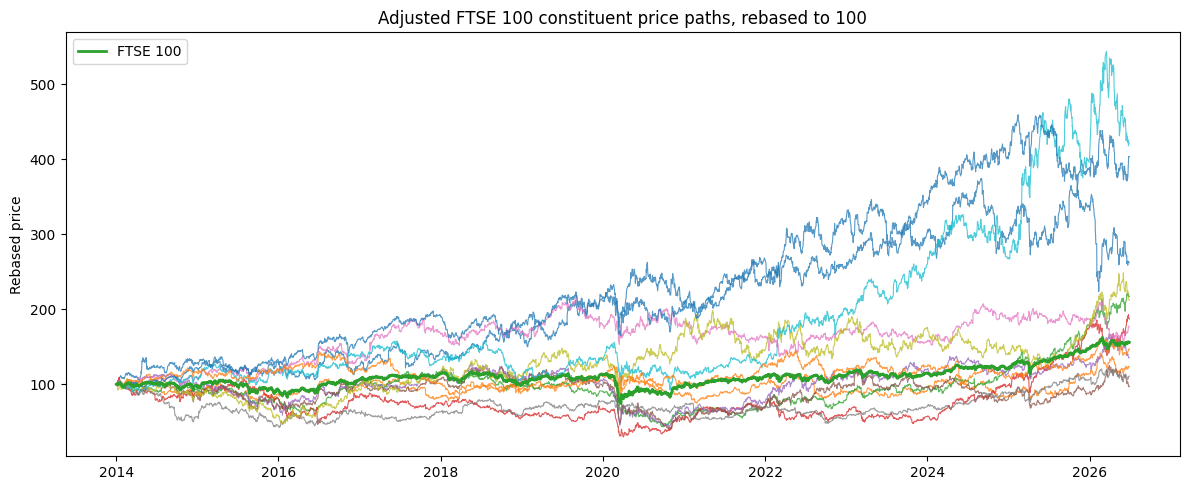

In [6]:
normalised = clean_prices.div(clean_prices.iloc[0]).mul(100)

fig, ax = plt.subplots(figsize=(12, 5))

for ticker in TICKERS:
    ax.plot(
        normalised.index,
        normalised[ticker],
        linewidth=0.8,
        alpha=0.75,
    )

ax.plot(
    normalised.index,
    normalised[BENCHMARK],
    linewidth=2.0,
    label="FTSE 100",
)

ax.set_title("Adjusted FTSE 100 constituent price paths, rebased to 100")
ax.set_ylabel("Rebased price")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 3. Market rationale and train-only unsupervised exploration

The FTSE 100 provides a liquid large-cap UK market with substantial sector and macroeconomic heterogeneity.

To avoid test leakage, hierarchical clustering and PCA use **training-period data only**. These analyses are descriptive; their labels are not inserted into the final supervised feature matrix.

In [7]:
train_prices = clean_prices.loc[
    clean_prices.index <= TRAIN_END,
    TICKERS + [BENCHMARK],
].copy()

train_returns = train_prices.pct_change().dropna()

stock_train_returns = train_returns[TICKERS]
benchmark_train_returns = train_returns[BENCHMARK]

annual_return = stock_train_returns.mean().mul(252)
annual_vol = stock_train_returns.std().mul(np.sqrt(252))

beta = stock_train_returns.apply(
    lambda s: s.cov(benchmark_train_returns)
    / benchmark_train_returns.var()
)

summary = pd.DataFrame({
    "Sector": pd.Series(SECTORS),
    "Annual_Return": annual_return,
    "Annual_Volatility": annual_vol,
    "Beta_to_FTSE": beta,
})

summary["Sharpe_rf0"] = (
    summary["Annual_Return"]
    / summary["Annual_Volatility"]
)

display(summary.sort_values("Sharpe_rf0", ascending=False))

,Sector,Annual_Return,Annual_Volatility,Beta_to_FTSE,Sharpe_rf0
AZN.L,Pharmaceuticals,0.1587,0.2488,0.7081,0.6378
REL.L,Information Services,0.1239,0.2023,0.7912,0.6128
BA.L,Aerospace & Defence,0.1037,0.2327,0.7723,0.4456
ULVR.L,Consumer Staples,0.0814,0.2062,0.6196,0.3948
RIO.L,Mining,0.1130,0.3228,1.2127,0.3499
NG.L,Utilities,0.0376,0.2026,0.6152,0.1857
SHEL.L,Energy,0.0547,0.3021,1.3464,0.1812
BP.L,Energy,0.0460,0.3118,1.3921,0.1475
GSK.L,Pharmaceuticals,0.0092,0.2057,0.7476,0.0449
HSBA.L,Banking,0.0037,0.2471,1.0561,0.0149


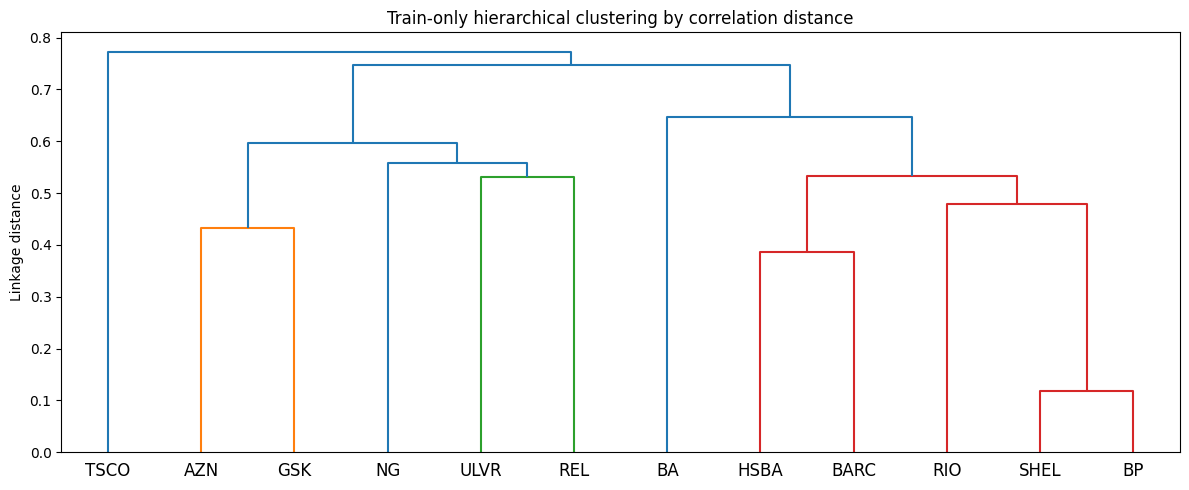

,Sector,Annual_Return,Annual_Volatility,Beta_to_FTSE,Sharpe_rf0,Behaviour_Cluster
ULVR.L,Consumer Staples,0.0814,0.2062,0.6196,0.3948,1
REL.L,Information Services,0.1239,0.2023,0.7912,0.6128,1
AZN.L,Pharmaceuticals,0.1587,0.2488,0.7081,0.6378,1
GSK.L,Pharmaceuticals,0.0092,0.2057,0.7476,0.0449,1
NG.L,Utilities,0.0376,0.2026,0.6152,0.1857,1
HSBA.L,Banking,0.0037,0.2471,1.0561,0.0149,2
BARC.L,Banking,0.0005,0.3445,1.4703,0.0016,2
SHEL.L,Energy,0.0547,0.3021,1.3464,0.1812,2
BP.L,Energy,0.0460,0.3118,1.3921,0.1475,2
RIO.L,Mining,0.1130,0.3228,1.2127,0.3499,2


In [8]:
corr_train = stock_train_returns.corr()

distance = 1.0 - corr_train
condensed = squareform(
    distance.values,
    checks=False,
)

Z = linkage(condensed, method="average")

fig, ax = plt.subplots(figsize=(12, 5))

dendrogram(
    Z,
    labels=[t.replace(".L", "") for t in TICKERS],
    ax=ax,
)

ax.set_title("Train-only hierarchical clustering by correlation distance")
ax.set_ylabel("Linkage distance")
plt.tight_layout()
plt.show()

cluster_ids = fcluster(
    Z,
    t=4,
    criterion="maxclust",
)

cluster_table = summary.copy()
cluster_table["Behaviour_Cluster"] = cluster_ids

display(
    cluster_table.sort_values(
        ["Behaviour_Cluster", "Sector"]
    )
)

,PC,Explained_Variance,Cumulative
0,1,0.4254,0.4254
1,2,0.2695,0.6949
2,3,0.1766,0.8714
3,4,0.1069,0.9783
4,5,0.0217,1.0000


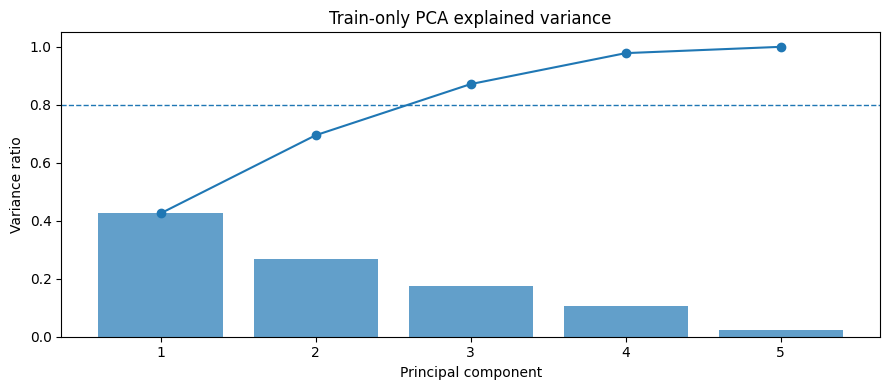

In [9]:
pca_characteristics = pd.DataFrame({
    "Annual_Return": annual_return,
    "Annual_Volatility": annual_vol,
    "Beta": beta,
    "Skew": stock_train_returns.skew(),
    "Kurtosis": stock_train_returns.kurtosis(),
})

pca_scaler = StandardScaler()
pca_X = pca_scaler.fit_transform(pca_characteristics)

pca = PCA(random_state=RANDOM_STATE)
pca.fit(pca_X)

pca_table = pd.DataFrame({
    "PC": np.arange(1, len(TICKERS) + 1)[:len(pca.explained_variance_ratio_)],
    "Explained_Variance": pca.explained_variance_ratio_,
    "Cumulative": np.cumsum(pca.explained_variance_ratio_),
})

display(pca_table)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(
    pca_table["PC"],
    pca_table["Explained_Variance"],
    alpha=0.7,
)
ax.plot(
    pca_table["PC"],
    pca_table["Cumulative"],
    marker="o",
)
ax.axhline(0.80, linestyle="--", linewidth=1)
ax.set_title("Train-only PCA explained variance")
ax.set_xlabel("Principal component")
ax.set_ylabel("Variance ratio")
plt.tight_layout()
plt.show()

## 4. Risk–return analysis and Monte Carlo portfolio optimisation

Portfolio statistics and the covariance matrix are estimated using the training period only. A 20,000-portfolio long-only Monte Carlo simulation identifies approximate MVP and maximum-Sharpe portfolios.

In [10]:
mu = stock_train_returns.mean().mul(252).values
cov = stock_train_returns.cov().mul(252).values

N_PORTFOLIOS = 20_000

rng = np.random.default_rng(RANDOM_STATE)

mc_weights = rng.dirichlet(
    np.ones(len(TICKERS)),
    size=N_PORTFOLIOS,
)

mc_return = mc_weights @ mu

mc_vol = np.sqrt(
    np.einsum(
        "ij,jk,ik->i",
        mc_weights,
        cov,
        mc_weights,
    )
)

mc_sharpe = mc_return / mc_vol

mc = pd.DataFrame({
    "Annual_Return": mc_return,
    "Annual_Volatility": mc_vol,
    "Sharpe": mc_sharpe,
})

mvp_idx = mc["Annual_Volatility"].idxmin()
max_sharpe_idx = mc["Sharpe"].idxmax()

weight_table = pd.DataFrame({
    "MVP": mc_weights[mvp_idx],
    "Max_Sharpe": mc_weights[max_sharpe_idx],
}, index=TICKERS)

print("Minimum-variance portfolio")
display(mc.loc[[mvp_idx]])

print("Maximum-Sharpe portfolio")
display(mc.loc[[max_sharpe_idx]])

display(weight_table)

Minimum-variance portfolio


,Annual_Return,Annual_Volatility,Sharpe
17933,0.0488,0.1441,0.3388


Maximum-Sharpe portfolio


,Annual_Return,Annual_Volatility,Sharpe
15150,0.1163,0.1656,0.7025


,MVP,Max_Sharpe
AZN.L,0.0251,0.2870
GSK.L,0.1145,0.0127
HSBA.L,0.0940,0.0013
BARC.L,0.0052,0.0042
SHEL.L,0.0108,0.0261
BP.L,0.0205,0.0440
ULVR.L,0.1463,0.0061
TSCO.L,0.1567,0.0218
RIO.L,0.0270,0.1468
BA.L,0.1441,0.0142


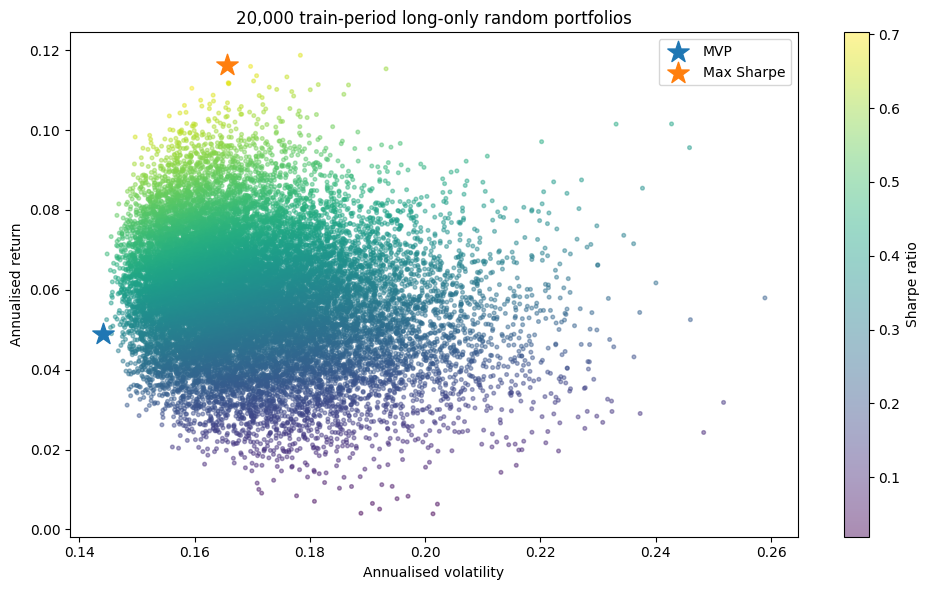

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(
    mc["Annual_Volatility"],
    mc["Annual_Return"],
    c=mc["Sharpe"],
    s=7,
    alpha=0.45,
)

ax.scatter(
    mc.loc[mvp_idx, "Annual_Volatility"],
    mc.loc[mvp_idx, "Annual_Return"],
    marker="*",
    s=260,
    label="MVP",
)

ax.scatter(
    mc.loc[max_sharpe_idx, "Annual_Volatility"],
    mc.loc[max_sharpe_idx, "Annual_Return"],
    marker="*",
    s=260,
    label="Max Sharpe",
)

ax.set_title("20,000 train-period long-only random portfolios")
ax.set_xlabel("Annualised volatility")
ax.set_ylabel("Annualised return")
ax.legend()

plt.colorbar(
    scatter,
    ax=ax,
    label="Sharpe ratio",
)

plt.tight_layout()
plt.show()

## 5. Data cleaning and train-only Isolation Forest

Isolation Forest is used as an **exploratory anomaly detector**, not as a supervised feature. It is fitted on training-period FTSE 100 returns and then applied to later observations without refitting on the locked test.

Keeping this detector outside the final predictive feature matrix prevents an unsupervised full-sample transformation from contaminating the supervised experiment.

In [12]:
benchmark_ret = daily_returns[BENCHMARK].dropna()

iso_train = pd.DataFrame({
    "Return": benchmark_ret,
    "Abs_Return": benchmark_ret.abs(),
    "Vol_20": benchmark_ret.rolling(20).std(),
}).dropna()

iso_fit = iso_train.loc[
    iso_train.index <= TRAIN_END
].copy()

iso = IsolationForest(
    n_estimators=300,
    contamination=0.01,
    random_state=RANDOM_STATE,
)

iso.fit(iso_fit)

iso_flags = pd.Series(
    iso.predict(iso_train) == -1,
    index=iso_train.index,
    name="Anomaly",
)

print("Training anomaly rate:", iso_flags.loc[:TRAIN_END].mean())
print("Post-training anomaly rate:", iso_flags.loc[iso_flags.index > TRAIN_END].mean())

extremes = pd.DataFrame({
    "FTSE_Return": benchmark_ret,
    "Anomaly": iso_flags.reindex(benchmark_ret.index).fillna(False),
})

display(
    extremes.loc[
        extremes["FTSE_Return"]
        .abs()
        .sort_values(ascending=False)
        .head(15)
        .index
    ]
)

Training anomaly rate: 0.01020408163265306
Post-training anomaly rate: 0.0022701475595913734


,FTSE_Return,Anomaly
Date,,
2020-03-12,-0.1087,True
2020-03-24,0.0905,True
2020-03-09,-0.0769,True
2020-03-27,-0.0525,True
2025-04-04,-0.0495,True
2020-11-09,0.0468,True
2015-08-24,-0.0467,True
2020-03-25,0.0445,True
2025-04-07,-0.0438,True


## 6. Feature Engineering

### Cross-Sectional Top-Quartile Target

The machine-learning strategy is designed to identify the stocks most likely to outperform the rest of the investment universe over the next five trading days.

Rather than forecasting the exact magnitude of future returns, the model estimates whether each stock will rank among the **top 3 of the 12-stock universe** based on its five-trading-day return relative to the FTSE 100 benchmark.

For each trading date:

1. Calculate each stock's five-trading-day forward log return.
2. Calculate the FTSE 100 five-trading-day forward log return.
3. Subtract the FTSE 100 return from each stock's return to obtain its benchmark-relative return.
4. Rank all 12 stocks cross-sectionally according to their benchmark-relative performance.
5. Assign a target value of `1` to the top 3 stocks and `0` to the remaining 9 stocks.

The target can therefore be expressed as:

\[
Y_{i,t} =
\begin{cases}
1, & \text{if stock } i \text{ ranks in the top 3 at time } t \\
0, & \text{otherwise}
\end{cases}
\]

Since three stocks are classified as positive from a universe of twelve, the positive-class proportion is:

\[
\frac{3}{12} = 25\%
\]

This formulation directly aligns the supervised-learning objective with the portfolio-construction process: the model learns to distinguish potential future relative outperformers rather than attempting to estimate highly noisy exact return values.

In [13]:
def compute_rsi(price, window=14):
    delta = price.diff()

    gain = delta.clip(lower=0.0)
    loss = -delta.clip(upper=0.0)

    avg_gain = gain.ewm(
        alpha=1.0 / window,
        adjust=False,
    ).mean()

    avg_loss = loss.ewm(
        alpha=1.0 / window,
        adjust=False,
    ).mean()

    rs = avg_gain / avg_loss.replace(0.0, np.nan)

    return 100.0 - 100.0 / (1.0 + rs)


def rolling_beta(stock_return, market_return, window=60):
    rolling_cov = stock_return.rolling(window).cov(
        market_return
    )

    rolling_var = market_return.rolling(window).var()

    return rolling_cov / rolling_var.replace(
        0.0,
        np.nan,
    )

In [14]:
stock_prices = clean_prices[TICKERS]
benchmark_price = clean_prices[BENCHMARK]

stock_returns = daily_returns[TICKERS]
ftse_returns = daily_returns[BENCHMARK]

market_positive_breadth = (
    stock_returns.gt(0.0).mean(axis=1)
)

market_above_ma50 = (
    stock_prices
    .gt(stock_prices.rolling(50).mean())
    .mean(axis=1)
)

feature_parts = []

for ticker in TICKERS:
    p = stock_prices[ticker]
    r = stock_returns[ticker]

    frame = pd.DataFrame(index=clean_prices.index)

    frame["Ticker"] = ticker

    frame["ret_1"] = r

    frame["reversal_2"] = -p.pct_change(2)
    frame["reversal_5"] = -p.pct_change(5)

    frame["mom_5"] = p.pct_change(5)
    frame["mom_20"] = p.pct_change(20)
    frame["mom_60"] = p.pct_change(60)

    frame["trend_20"] = (
        p / p.rolling(20).mean() - 1.0
    )

    frame["trend_60"] = (
        p / p.rolling(60).mean() - 1.0
    )

    frame["vol_20"] = (
        r.rolling(20).std()
        * np.sqrt(252)
    )

    frame["vol_60"] = (
        r.rolling(60).std()
        * np.sqrt(252)
    )

    frame["vol_compression"] = (
        frame["vol_20"]
        / frame["vol_60"]
        - 1.0
    )

    frame["rsi_14"] = compute_rsi(
        p,
        14,
    )

    frame["rel_strength_20"] = (
        p.pct_change(20)
        - benchmark_price.pct_change(20)
    )

    frame["rel_strength_60"] = (
        p.pct_change(60)
        - benchmark_price.pct_change(60)
    )

    frame["beta_60"] = rolling_beta(
        r,
        ftse_returns,
        60,
    )

    frame["drawdown_63"] = (
        p / p.rolling(63).max() - 1.0
    )

    frame["volume_shock_20"] = (
        clean_volume[ticker]
        / clean_volume[ticker].rolling(20).mean()
        - 1.0
    )

    frame["breadth_positive"] = market_positive_breadth
    frame["breadth_above_ma50"] = market_above_ma50

    frame["ftse_mom_20"] = (
        benchmark_price.pct_change(20)
    )

    frame["ftse_vol_20"] = (
        ftse_returns.rolling(20).std()
        * np.sqrt(252)
    )

    frame["ftse_trend_100"] = (
        benchmark_price
        / benchmark_price.rolling(100).mean()
        - 1.0
    )

    stock_forward_log = (
        np.log(
            p.shift(-HORIZON)
            / p
        )
    )

    benchmark_forward_log = (
        np.log(
            benchmark_price.shift(-HORIZON)
            / benchmark_price
        )
    )

    frame["forward_relative_log_return"] = (
        stock_forward_log
        - benchmark_forward_log
    )

    feature_parts.append(frame)

panel = (
    pd.concat(feature_parts)
    .reset_index()
    .rename(columns={"index": "Date"})
    .sort_values(["Date", "Ticker"])
    .reset_index(drop=True)
)

display(panel.tail())

,Date,Ticker,ret_1,reversal_2,reversal_5,mom_5,mom_20,mom_60,trend_20,trend_60,...,rel_strength_60,beta_60,drawdown_63,volume_shock_20,breadth_positive,breadth_above_ma50,ftse_mom_20,ftse_vol_20,ftse_trend_100,forward_relative_log_return
37855,2026-06-29,REL.L,-0.0013,0.0038,-0.0137,0.0137,-0.0720,-0.0467,-0.0366,-0.0633,...,-0.0769,0.1643,-0.1506,-0.4061,0.4167,0.5000,0.0140,0.1034,0.0078,NaN
37856,2026-06-29,RIO.L,-0.0128,0.0153,0.0582,-0.0582,-0.1211,0.0190,-0.0674,-0.0650,...,-0.0112,1.2618,-0.1483,-0.4018,0.4167,0.5000,0.0140,0.1034,0.0078,NaN
37857,2026-06-29,SHEL.L,0.0009,0.0085,0.0359,-0.0359,-0.0925,-0.1904,-0.0632,-0.0982,...,-0.2206,-0.5080,-0.1904,-0.1425,0.4167,0.5000,0.0140,0.1034,0.0078,NaN
37858,2026-06-29,TSCO.L,0.0024,-0.0132,-0.0260,0.0260,0.0576,-0.0254,0.0132,-0.0103,...,-0.0556,0.5493,-0.0683,0.2107,0.4167,0.5000,0.0140,0.1034,0.0078,NaN
37859,2026-06-29,ULVR.L,-0.0045,-0.0001,-0.0427,0.0427,0.1083,0.0908,0.0512,0.0678,...,0.0606,0.6071,-0.0045,-0.3818,0.4167,0.5000,0.0140,0.1034,0.0078,NaN


In [15]:
valid_target = panel[
    "forward_relative_log_return"
].notna()

panel["future_rank"] = np.nan

panel.loc[
    valid_target,
    "future_rank",
] = (
    panel.loc[valid_target]
    .groupby("Date")[
        "forward_relative_log_return"
    ]
    .rank(
        ascending=False,
        method="first",
    )
)

panel["Target_TopQuartile_5D"] = np.nan

panel.loc[
    valid_target,
    "Target_TopQuartile_5D",
] = (
    panel.loc[
        valid_target,
        "future_rank",
    ]
    .le(TOP_K)
    .astype(int)
)

target_audit = (
    panel.dropna(
        subset=["Target_TopQuartile_5D"]
    )
    .groupby("Date")[
        "Target_TopQuartile_5D"
    ]
    .sum()
)

print("Positive names per date:")
print(target_audit.value_counts().sort_index())

assert target_audit.eq(TOP_K).all(), (
    "Every complete target date should have "
    f"exactly {TOP_K} positive stocks."
)

print(
    "Overall positive-class share:",
    panel["Target_TopQuartile_5D"].mean(),
)

Positive names per date:
Target_TopQuartile_5D
3.0000    3150
Name: count, dtype: int64
Overall positive-class share: 0.25


### Cross-sectional rank features

Raw indicators are supplemented with percentile ranks calculated independently on each date. These features are aligned with the stock-selection objective and are invariant to changing absolute indicator scales through time.

In [16]:
RANK_SOURCE_FEATURES = [
    "mom_20",
    "mom_60",
    "reversal_5",
    "vol_20",
    "rel_strength_20",
    "rsi_14",
    "drawdown_63",
]

for feature in RANK_SOURCE_FEATURES:
    panel[
        f"rank_{feature}"
    ] = (
        panel.groupby("Date")[feature]
        .rank(pct=True)
    )

BASE_FEATURES = [
    "ret_1",
    "reversal_2",
    "reversal_5",
    "mom_5",
    "mom_20",
    "mom_60",
    "trend_20",
    "trend_60",
    "vol_20",
    "vol_60",
    "vol_compression",
    "rsi_14",
    "rel_strength_20",
    "rel_strength_60",
    "beta_60",
    "drawdown_63",
    "volume_shock_20",
    "breadth_positive",
    "breadth_above_ma50",
    "ftse_mom_20",
    "ftse_vol_20",
    "ftse_trend_100",
]

RANK_FEATURES = [
    f"rank_{feature}"
    for feature in RANK_SOURCE_FEATURES
]

## 7. Causal Hidden Markov Model regime engine

The HMM uses FTSE 100:

- daily return;
- 20-day realised volatility;
- 63-day drawdown.

It is not fitted once on the complete sample. Instead:

1. wait for a minimum two-year history;
2. fit the HMM and scaler on the history available at that point;
3. identify the high-volatility state from the historical state characteristics;
4. identify the highest-return state from historical characteristics;
5. freeze the model for the next 63 trading sessions;
6. repeat on an expanding window.

The supervised model receives **causal posterior probabilities**, not a future-informed hard regime label.

In [17]:
hmm_input = pd.DataFrame(
    index=clean_prices.index
)

hmm_input["ret"] = ftse_returns

hmm_input["vol_20"] = (
    ftse_returns.rolling(20).std()
    * np.sqrt(252)
)

hmm_input["dd_63"] = (
    benchmark_price
    / benchmark_price.rolling(63).max()
    - 1.0
)

hmm_input = hmm_input.dropna()

N_STATES = 3
MIN_HMM_HISTORY = 252 * 2
HMM_REFIT_EVERY = 63

regime_features = pd.DataFrame(
    index=hmm_input.index,
    columns=[
        "hmm_prob_turbulent",
        "hmm_prob_bull",
    ],
    dtype=float,
)

hmm_audit_rows = []

for start in range(
    MIN_HMM_HISTORY,
    len(hmm_input),
    HMM_REFIT_EVERY,
):
    train_slice = hmm_input.iloc[:start].copy()

    forecast_slice = hmm_input.iloc[
        start:min(
            start + HMM_REFIT_EVERY,
            len(hmm_input),
        )
    ].copy()

    if forecast_slice.empty:
        continue

    scaler = StandardScaler()

    X_train_hmm = scaler.fit_transform(
        train_slice
    )

    model = GaussianHMM(
        n_components=N_STATES,
        covariance_type="diag",
        n_iter=300,
        random_state=RANDOM_STATE,
    )

    model.fit(X_train_hmm)

    train_states = model.predict(
        X_train_hmm
    )

    state_characteristics = (
        train_slice.assign(
            state=train_states
        )
        .groupby("state")
        .agg(
            mean_return=("ret", "mean"),
            mean_volatility=("vol_20", "mean"),
            mean_drawdown=("dd_63", "mean"),
        )
    )

    turbulent_state = int(
        state_characteristics[
            "mean_volatility"
        ].idxmax()
    )

    bull_state = int(
        state_characteristics[
            "mean_return"
        ].idxmax()
    )

    X_forecast_hmm = scaler.transform(
        forecast_slice
    )

    probabilities = model.predict_proba(
        X_forecast_hmm
    )

    regime_features.loc[
        forecast_slice.index,
        "hmm_prob_turbulent",
    ] = probabilities[:, turbulent_state]

    regime_features.loc[
        forecast_slice.index,
        "hmm_prob_bull",
    ] = probabilities[:, bull_state]

    hmm_audit_rows.append({
        "fit_through": train_slice.index[-1],
        "forecast_start": forecast_slice.index[0],
        "forecast_end": forecast_slice.index[-1],
        "turbulent_state": turbulent_state,
        "bull_state": bull_state,
    })

hmm_audit = pd.DataFrame(
    hmm_audit_rows
)

display(hmm_audit.tail())

,fit_through,forecast_start,forecast_end,turbulent_state,bull_state
37,2025-06-20,2025-06-23,2025-09-18,1,2
38,2025-09-18,2025-09-19,2025-12-16,2,0
39,2025-12-16,2025-12-17,2026-03-18,2,1
40,2026-03-18,2026-03-19,2026-06-19,1,2
41,2026-06-19,2026-06-22,2026-06-29,2,0


In [18]:
panel = panel.merge(
    regime_features,
    left_on="Date",
    right_index=True,
    how="left",
)

MODEL_FEATURES = (
    BASE_FEATURES
    + RANK_FEATURES
    + [
        "hmm_prob_turbulent",
        "hmm_prob_bull",
    ]
)

model_data = panel.dropna(
    subset=MODEL_FEATURES
    + [
        "Target_TopQuartile_5D",
        "forward_relative_log_return",
    ]
).copy()

model_data[
    "Target_TopQuartile_5D"
] = model_data[
    "Target_TopQuartile_5D"
].astype(int)

print("Final modelling rows:", len(model_data))
print(
    "Final modelling range:",
    model_data["Date"].min().date(),
    "to",
    model_data["Date"].max().date(),
)

Final modelling rows: 31008
Final modelling range: 2016-03-30 to 2026-06-22


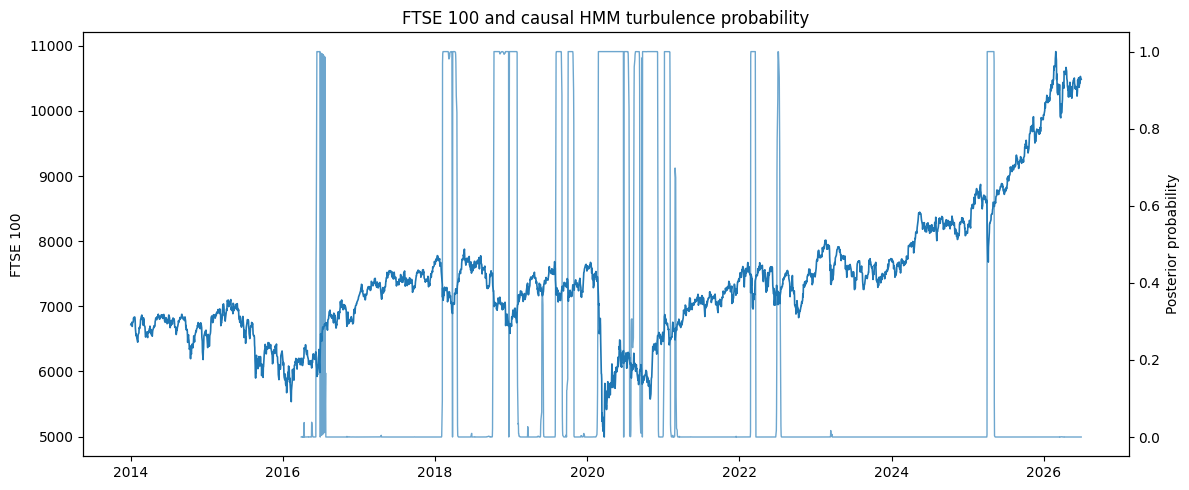

In [19]:
regime_plot = regime_features.dropna()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    benchmark_price.index,
    benchmark_price.values,
    linewidth=1.2,
    label="FTSE 100",
)

ax2 = ax.twinx()

ax2.plot(
    regime_plot.index,
    regime_plot["hmm_prob_turbulent"],
    linewidth=1.0,
    alpha=0.65,
    label="P(turbulent)",
)

ax.set_title("FTSE 100 and causal HMM turbulence probability")
ax.set_ylabel("FTSE 100")
ax2.set_ylabel("Posterior probability")
plt.tight_layout()
plt.show()

## 8. Chronological train / calibration / validation / locked-test split

Four chronological regions are used:

- **Training:** model fitting and purged hyperparameter optimisation.
- **Calibration:** probability calibration only.
- **Validation:** confidence-threshold selection and strategy decisions.
- **Locked test:** final evaluation only.

No decision is changed after seeing the locked test.

In [20]:
train = model_data.loc[
    model_data["Date"] <= TRAIN_END
].copy()

calibration = model_data.loc[
    (model_data["Date"] > TRAIN_END)
    & (
        model_data["Date"]
        <= CALIBRATION_END
    )
].copy()

validation = model_data.loc[
    (
        model_data["Date"]
        > CALIBRATION_END
    )
    & (
        model_data["Date"]
        <= VALIDATION_END
    )
].copy()

test = model_data.loc[
    model_data["Date"] >= TEST_START
].copy()

for name, frame in {
    "TRAIN": train,
    "CALIBRATION": calibration,
    "VALIDATION": validation,
    "LOCKED_TEST": test,
}.items():
    print(
        name,
        len(frame),
        frame["Date"].min().date(),
        "to",
        frame["Date"].max().date(),
        "positive share=",
        round(
            frame[
                "Target_TopQuartile_5D"
            ].mean(),
            4,
        ),
    )

TRAIN 20496 2016-03-30 to 2022-12-30 positive share= 0.25
CALIBRATION 1488 2023-01-03 to 2023-06-30 positive share= 0.25
VALIDATION 1524 2023-07-03 to 2023-12-29 positive share= 0.25
LOCKED_TEST 7500 2024-01-02 to 2026-06-22 positive share= 0.25


## 9. Purged grouped-date cross-validation

A normal row-based `TimeSeriesSplit` is inappropriate for cross-sectional panel data because it can split different stocks from the same trading date across train and validation.

The custom splitter below:

- keeps **all stocks from each date together**;
- uses expanding historical training windows;
- validates only on later dates;
- removes the five trading dates immediately before each validation block to prevent overlapping five-day target leakage.

In [21]:
class PurgedGroupedDateSplit(BaseCrossValidator):
    def __init__(
        self,
        dates,
        n_splits=5,
        embargo=5,
        min_train_fraction=0.45,
    ):
        self.dates = pd.Series(
            pd.to_datetime(dates)
        ).reset_index(drop=True)

        self.n_splits = n_splits
        self.embargo = embargo
        self.min_train_fraction = (
            min_train_fraction
        )

    def get_n_splits(
        self,
        X=None,
        y=None,
        groups=None,
    ):
        return self.n_splits

    def split(
        self,
        X,
        y=None,
        groups=None,
    ):
        unique_dates = np.array(
            sorted(
                self.dates.unique()
            )
        )

        n_dates = len(unique_dates)

        min_train_dates = int(
            n_dates
            * self.min_train_fraction
        )

        remaining = (
            n_dates
            - min_train_dates
            - self.embargo
        )

        validation_size = max(
            remaining // self.n_splits,
            1,
        )

        for fold in range(
            self.n_splits
        ):
            val_start = (
                min_train_dates
                + self.embargo
                + fold * validation_size
            )

            if fold == (
                self.n_splits - 1
            ):
                val_end = n_dates
            else:
                val_end = min(
                    val_start
                    + validation_size,
                    n_dates,
                )

            train_end = (
                val_start
                - self.embargo
            )

            train_dates = set(
                unique_dates[:train_end]
            )

            validation_dates = set(
                unique_dates[
                    val_start:val_end
                ]
            )

            train_idx = np.flatnonzero(
                self.dates.isin(
                    train_dates
                ).values
            )

            validation_idx = np.flatnonzero(
                self.dates.isin(
                    validation_dates
                ).values
            )

            if (
                len(train_idx) > 0
                and len(validation_idx) > 0
            ):
                yield (
                    train_idx,
                    validation_idx,
                )

In [22]:
train = (
    train.sort_values(
        ["Date", "Ticker"]
    )
    .reset_index(drop=True)
)

X_train = train[MODEL_FEATURES]
y_train = train[
    "Target_TopQuartile_5D"
]

cv = PurgedGroupedDateSplit(
    dates=train["Date"],
    n_splits=5,
    embargo=EMBARGO,
)

cv_splits = list(
    cv.split(X_train)
)

for i, (tr_idx, va_idx) in enumerate(
    cv_splits,
    start=1,
):
    train_dates_fold = train.loc[
        tr_idx,
        "Date",
    ]

    valid_dates_fold = train.loc[
        va_idx,
        "Date",
    ]

    print(
        f"Fold {i}:",
        train_dates_fold.min().date(),
        "→",
        train_dates_fold.max().date(),
        "| validation:",
        valid_dates_fold.min().date(),
        "→",
        valid_dates_fold.max().date(),
    )

    assert (
        train_dates_fold.max()
        < valid_dates_fold.min()
    )

Fold 1: 2016-03-30 → 2019-04-09 | validation: 2019-04-17 → 2020-01-14
Fold 2: 2016-03-30 → 2020-01-07 | validation: 2020-01-15 → 2020-10-08
Fold 3: 2016-03-30 → 2020-10-01 | validation: 2020-10-09 → 2021-07-07
Fold 4: 2016-03-30 → 2021-06-30 | validation: 2021-07-08 → 2022-03-31
Fold 5: 2016-03-30 → 2022-03-24 | validation: 2022-04-01 → 2022-12-30


## 10. Model families and RandomizedSearchCV

Three model families are compared:

1. **Regularised Logistic Regression** — transparent linear probability baseline.
2. **Random Forest** — nonlinear bagged-tree model.
3. **Histogram Gradient Boosting** — nonlinear boosting model.

Hyperparameters are selected using `RandomizedSearchCV` with the purged grouped-date folds. The search objective is training-period validation ROC-AUC.

The final strategy is an ensemble; no model is selected by examining locked-test results.

In [23]:
logistic = Pipeline([
    (
        "scale",
        RobustScaler(),
    ),
    (
        "select",
        SelectKBest(
            score_func=mutual_info_classif,
            k=15,
        ),
    ),
    (
        "model",
        LogisticRegression(
            max_iter=5000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
    ),
])

logistic_params = {
    "select__k": [
        12,
        16,
        20,
        "all",
    ],
    "model__C": np.logspace(
        -3,
        1,
        25,
    ),
    "model__penalty": [
        "l1",
        "l2",
    ],
    "model__solver": [
        "liblinear",
    ],
}

logistic_search = RandomizedSearchCV(
    estimator=logistic,
    param_distributions=logistic_params,
    n_iter=20,
    scoring="roc_auc",
    cv=cv_splits,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
)

logistic_search.fit(
    X_train,
    y_train,
)

print("Logistic best ROC-AUC:", logistic_search.best_score_)
print(logistic_search.best_params_)

Logistic best ROC-AUC: 0.5430062393887496
{'select__k': 20, 'model__solver': 'liblinear', 'model__penalty': 'l2', 'model__C': np.float64(1.467799267622069)}


In [24]:
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    class_weight="balanced_subsample",
    n_jobs=1,
)

rf_params = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 7],
    "min_samples_leaf": [10, 20, 30],
    "max_features": [0.5, 0.7],
}

rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_params,
    n_iter=6,
    scoring="roc_auc",
    cv=cv_splits,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=2,
    refit=True,
)

rf_search.fit(
    X_train,
    y_train,
)

print("RandomForest best ROC-AUC:", rf_search.best_score_)
print(rf_search.best_params_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END max_depth=7, max_features=0.7, min_samples_leaf=30, n_estimators=100; total time=  12.7s
[CV] END max_depth=7, max_features=0.7, min_samples_leaf=30, n_estimators=100; total time=  15.6s
[CV] END max_depth=7, max_features=0.7, min_samples_leaf=30, n_estimators=100; total time=  20.5s
[CV] END max_depth=7, max_features=0.7, min_samples_leaf=30, n_estimators=100; total time=  21.7s
[CV] END max_depth=7, max_features=0.7, min_samples_leaf=30, n_estimators=100; total time=  25.9s
[CV] END max_depth=5, max_features=0.5, min_samples_leaf=10, n_estimators=100; total time=   7.4s
[CV] END max_depth=5, max_features=0.5, min_samples_leaf=10, n_estimators=100; total time=   8.0s
[CV] END max_depth=5, max_features=0.5, min_samples_leaf=10, n_estimators=100; total time=  10.5s
[CV] END max_depth=5, max_features=0.5, min_samples_leaf=10, n_estimators=100; total time=  12.4s
[CV] END max_depth=5, max_features=0.5, min_samples_leaf=1

In [25]:
hgb = HistGradientBoostingClassifier(
    random_state=RANDOM_STATE,
)

hgb_params = {
    "learning_rate": [
        0.02,
        0.04,
        0.06,
        0.10,
    ],
    "max_iter": [
        150,
        250,
        400,
    ],
    "max_leaf_nodes": [
        7,
        15,
        31,
    ],
    "min_samples_leaf": [
        10,
        20,
        40,
    ],
    "l2_regularization": [
        0.0,
        0.01,
        0.1,
        1.0,
    ],
}

hgb_search = RandomizedSearchCV(
    estimator=hgb,
    param_distributions=hgb_params,
    n_iter=20,
    scoring="roc_auc",
    cv=cv_splits,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
)

hgb_search.fit(
    X_train,
    y_train,
)

print("HistGradientBoosting best ROC-AUC:", hgb_search.best_score_)
print(hgb_search.best_params_)

HistGradientBoosting best ROC-AUC: 0.5342712010532079
{'min_samples_leaf': 10, 'max_leaf_nodes': 7, 'max_iter': 250, 'learning_rate': 0.1, 'l2_regularization': 1.0}


In [26]:
search_summary = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "HistGradientBoosting",
    ],
    "Purged_CV_ROC_AUC": [
        logistic_search.best_score_,
        rf_search.best_score_,
        hgb_search.best_score_,
    ],
}).set_index("Model")

display(
    search_summary.sort_values(
        "Purged_CV_ROC_AUC",
        ascending=False,
    )
)

,Purged_CV_ROC_AUC
Model,
Logistic Regression,0.5430
HistGradientBoosting,0.5343
Random Forest,0.5236


## 11. Chronological probability calibration

Tree-model probabilities are often poorly calibrated. The base models are therefore:

1. fitted on the training period;
2. applied to the first half of 2023;
3. mapped through a one-variable logistic calibration model.

The calibration mapping is then frozen and used unchanged on validation and locked test data.

In [27]:
best_models = {
    "Logistic": logistic_search.best_estimator_,
    "RandomForest": rf_search.best_estimator_,
    "HGB": hgb_search.best_estimator_,
}

X_cal = calibration[MODEL_FEATURES]
y_cal = calibration[
    "Target_TopQuartile_5D"
]

calibrators = {}

for name, model in best_models.items():
    raw_cal_probability = (
        model.predict_proba(
            X_cal
        )[:, 1]
    )

    calibrator = LogisticRegression(
        C=1.0,
        solver="lbfgs",
        random_state=RANDOM_STATE,
    )

    calibrator.fit(
        raw_cal_probability.reshape(
            -1,
            1,
        ),
        y_cal,
    )

    calibrators[name] = calibrator

    calibrated_probability = (
        calibrator.predict_proba(
            raw_cal_probability.reshape(
                -1,
                1,
            )
        )[:, 1]
    )

    print(
        name,
        "| raw Brier:",
        round(
            brier_score_loss(
                y_cal,
                raw_cal_probability,
            ),
            5,
        ),
        "| calibrated Brier:",
        round(
            brier_score_loss(
                y_cal,
                calibrated_probability,
            ),
            5,
        ),
    )

Logistic | raw Brier: 0.24526 | calibrated Brier: 0.18628
RandomForest | raw Brier: 0.24487 | calibrated Brier: 0.18683
HGB | raw Brier: 0.19557 | calibrated Brier: 0.18747


In [28]:
def calibrated_ensemble_probability(
    frame,
):
    X = frame[MODEL_FEATURES]

    calibrated_columns = []

    for name, model in best_models.items():
        raw_probability = (
            model.predict_proba(
                X
            )[:, 1]
        )

        calibrated_probability = (
            calibrators[
                name
            ].predict_proba(
                raw_probability.reshape(
                    -1,
                    1,
                )
            )[:, 1]
        )

        calibrated_columns.append(
            calibrated_probability
        )

    calibrated_matrix = np.column_stack(
        calibrated_columns
    )

    return calibrated_matrix.mean(
        axis=1
    )


validation[
    "Ensemble_Probability"
] = calibrated_ensemble_probability(
    validation
)

test[
    "Ensemble_Probability"
] = calibrated_ensemble_probability(
    test
)

## 12. Validation diagnostics

The strategy is evaluated as a ranking problem as well as a classifier.

The most relevant diagnostics are:

- ROC-AUC;
- precision and recall;
- probability calibration;
- **Precision@3**: how many of the three highest-probability stocks actually finish in the future top 3;
- average realised five-day relative return of the top-3 predictions.

In [29]:
def precision_at_k(
    frame,
    probability_col,
    target_col,
    k=3,
):
    daily_values = []

    for _, group in frame.groupby(
        "Date"
    ):
        if len(group) < k:
            continue

        selected = group.nlargest(
            k,
            probability_col,
        )

        daily_values.append(
            selected[
                target_col
            ].mean()
        )

    return float(
        np.mean(daily_values)
    )


def topk_relative_return(
    frame,
    probability_col,
    return_col,
    k=3,
):
    daily_values = []

    for _, group in frame.groupby(
        "Date"
    ):
        if len(group) < k:
            continue

        selected = group.nlargest(
            k,
            probability_col,
        )

        daily_values.append(
            selected[
                return_col
            ].mean()
        )

    return float(
        np.mean(daily_values)
    )


validation_prediction = (
    validation[
        "Ensemble_Probability"
    ]
    >= 0.25
).astype(int)

validation_metrics = pd.Series({
    "ROC_AUC": roc_auc_score(
        validation[
            "Target_TopQuartile_5D"
        ],
        validation[
            "Ensemble_Probability"
        ],
    ),
    "Accuracy_at_0.25": accuracy_score(
        validation[
            "Target_TopQuartile_5D"
        ],
        validation_prediction,
    ),
    "Precision_at_0.25": precision_score(
        validation[
            "Target_TopQuartile_5D"
        ],
        validation_prediction,
        zero_division=0,
    ),
    "Recall_at_0.25": recall_score(
        validation[
            "Target_TopQuartile_5D"
        ],
        validation_prediction,
        zero_division=0,
    ),
    "F1_at_0.25": f1_score(
        validation[
            "Target_TopQuartile_5D"
        ],
        validation_prediction,
        zero_division=0,
    ),
    "Log_Loss": log_loss(
        validation[
            "Target_TopQuartile_5D"
        ],
        validation[
            "Ensemble_Probability"
        ],
    ),
    "Brier": brier_score_loss(
        validation[
            "Target_TopQuartile_5D"
        ],
        validation[
            "Ensemble_Probability"
        ],
    ),
    "Precision_at_3": precision_at_k(
        validation,
        "Ensemble_Probability",
        "Target_TopQuartile_5D",
        k=TOP_K,
    ),
    "Mean_Top3_Relative_Log_Return": topk_relative_return(
        validation,
        "Ensemble_Probability",
        "forward_relative_log_return",
        k=TOP_K,
    ),
})

display(
    validation_metrics.to_frame(
        "Validation"
    )
)

,Validation
ROC_AUC,0.5297
Accuracy_at_0.25,0.5610
Precision_at_0.25,0.2677
Recall_at_0.25,0.4357
F1_at_0.25,0.3317
Log_Loss,0.5616
Brier,0.1872
Precision_at_3,0.2808
Mean_Top3_Relative_Log_Return,0.0011


## 13. Corrected weekly five-day backtest engine

### Signal and execution mechanics

The portfolio engine uses the actual market calendar.

For each calendar week:

1. take the final available trading date **on or before Friday** as the signal date;
2. form the portfolio using information at that close;
3. execute on the **next trading session**;
4. hold that sleeve for exactly **five trading sessions**;
5. calculate daily close-to-close P&L beginning after the execution close;
6. if a holiday creates overlap between adjacent five-day sleeves, average active sleeve weights so gross exposure does not exceed the designed level;
7. charge transaction costs only when aggregate target weights change.

### Turnover buffer

A stock already held by the prior sleeve can remain if:

- its current probability remains above a lower hold threshold; and
- its current probability rank is no worse than 5.

This avoids selling a stock merely because it moves from rank 3 to rank 4.

In [30]:
next_day_stock_return = (
    clean_prices[TICKERS]
    .pct_change()
    .shift(-1)
)

next_day_ftse_return = (
    clean_prices[BENCHMARK]
    .pct_change()
    .shift(-1)
)

rolling_vol_20 = (
    clean_prices[TICKERS]
    .pct_change()
    .rolling(20)
    .std()
    * np.sqrt(252)
)


def weekly_signal_dates(
    available_prediction_dates,
):
    dates = pd.DatetimeIndex(
        sorted(
            pd.to_datetime(
                available_prediction_dates
            ).unique()
        )
    )

    by_week = (
        pd.Series(
            dates,
            index=dates,
        )
        .groupby(
            dates.to_period(
                "W-FRI"
            )
        )
        .max()
    )

    return pd.DatetimeIndex(
        by_week.values
    )

In [31]:
def construct_signal_portfolio(
    signal_frame,
    previous_names,
    entry_threshold,
    hold_threshold,
    top_k=TOP_K,
    buffer_rank=BUFFER_RANK,
):
    scores = (
        signal_frame
        .set_index("Ticker")[
            "Ensemble_Probability"
        ]
        .sort_values(
            ascending=False
        )
    )

    ranks = scores.rank(
        ascending=False,
        method="first",
    )

    keepers = [
        ticker
        for ticker in previous_names
        if (
            ticker in scores.index
            and scores.loc[ticker]
            >= hold_threshold
            and ranks.loc[ticker]
            <= buffer_rank
        )
    ]

    selected = keepers[:top_k]

    for ticker in scores.index:
        if len(selected) >= top_k:
            break

        if ticker in selected:
            continue

        if scores.loc[ticker] >= entry_threshold:
            selected.append(ticker)

    return selected

In [32]:
def regime_exposure(
    signal_frame,
):
    first_row = signal_frame.iloc[0]

    turbulence_probability = float(
        first_row[
            "hmm_prob_turbulent"
        ]
    )

    trend_positive = bool(
        first_row[
            "ftse_trend_100"
        ]
        > 0.0
    )

    exposure = np.clip(
        1.0
        - 0.75
        * turbulence_probability,
        0.25,
        1.0,
    )

    if not trend_positive:
        exposure *= 0.75

    return float(
        np.clip(
            exposure,
            0.0,
            1.0,
        )
    )

In [33]:
def build_weekly_sleeve_weights(
    prediction_frame,
    entry_threshold,
    use_regime=True,
    use_buffer=True,
    transaction_cost=TRANSACTION_COST,
):
    prediction_frame = (
        prediction_frame
        .sort_values(
            ["Date", "Ticker"]
        )
        .copy()
    )

    available_prediction_dates = (
        prediction_frame[
            "Date"
        ].unique()
    )

    signal_dates = weekly_signal_dates(
        available_prediction_dates
    )

    all_market_dates = clean_prices.index

    active_sleeves = {}
    signal_log = []

    previous_names = []

    hold_threshold = max(
        0.0,
        entry_threshold - 0.05,
    )

    for signal_date in signal_dates:
        day_frame = prediction_frame.loc[
            prediction_frame[
                "Date"
            ]
            == signal_date
        ].copy()

        if len(day_frame) < len(TICKERS):
            continue

        future_dates = all_market_dates[
            all_market_dates
            > signal_date
        ]

        if len(future_dates) < HORIZON:
            continue

        execution_date = future_dates[0]

        holding_dates = future_dates[
            :HORIZON
        ]

        selected = construct_signal_portfolio(
            signal_frame=day_frame,
            previous_names=(
                previous_names
                if use_buffer
                else []
            ),
            entry_threshold=entry_threshold,
            hold_threshold=hold_threshold,
            top_k=TOP_K,
            buffer_rank=BUFFER_RANK,
        )

        previous_names = selected.copy()

        target = pd.Series(
            0.0,
            index=TICKERS,
        )

        if selected:
            selected_vol = (
                rolling_vol_20
                .reindex(
                    [signal_date]
                )[selected]
                .iloc[0]
                .replace(
                    0.0,
                    np.nan,
                )
            )

            inverse_vol = (
                1.0
                / selected_vol
            )

            base_weights = (
                inverse_vol
                / inverse_vol.sum()
            )

            base_weights = (
                base_weights
                .clip(
                    upper=MAX_POSITION
                )
            )

            if base_weights.sum() > 0:
                base_weights = (
                    base_weights
                    / base_weights.sum()
                )

            confidence_fraction = (
                len(selected)
                / TOP_K
            )

            if use_regime:
                exposure = regime_exposure(
                    day_frame
                )
            else:
                exposure = 1.0

            gross_target = (
                confidence_fraction
                * exposure
            )

            target.loc[
                selected
            ] = (
                base_weights.values
                * gross_target
            )
        else:
            exposure = 0.0

        sleeve_id = str(
            signal_date.date()
        )

        active_sleeves[
            sleeve_id
        ] = {
            "signal_date": signal_date,
            "execution_date": execution_date,
            "holding_dates": holding_dates,
            "weights": target,
        }

        signal_log.append({
            "signal_date": signal_date,
            "execution_date": execution_date,
            "selected": ", ".join(selected),
            "n_selected": len(selected),
            "gross_exposure": target.sum(),
        })

    if not active_sleeves:
        raise ValueError(
            "No valid trading sleeves were created."
        )

    first_holding_date = min(
        sleeve[
            "holding_dates"
        ][0]
        for sleeve
        in active_sleeves.values()
    )

    last_holding_date = max(
        sleeve[
            "holding_dates"
        ][-1]
        for sleeve
        in active_sleeves.values()
    )

    pnl_dates = all_market_dates[
        (
            all_market_dates
            >= first_holding_date
        )
        & (
            all_market_dates
            <= last_holding_date
        )
    ]

    aggregate_weights = pd.DataFrame(
        0.0,
        index=pnl_dates,
        columns=TICKERS,
    )

    for date in pnl_dates:
        sleeves_today = [
            sleeve["weights"]
            for sleeve
            in active_sleeves.values()
            if date in sleeve[
                "holding_dates"
            ]
        ]

        if sleeves_today:
            aggregate_weights.loc[
                date
            ] = pd.concat(
                sleeves_today,
                axis=1,
            ).mean(
                axis=1
            )

    turnover = (
        aggregate_weights
        .diff()
        .abs()
        .sum(axis=1)
    )

    if len(turnover) > 0:
        turnover.iloc[0] = (
            aggregate_weights
            .iloc[0]
            .abs()
            .sum()
        )

    gross_return = (
        aggregate_weights
        * next_day_stock_return
        .reindex(
            aggregate_weights.index
        )
    ).sum(axis=1)

    cost = (
        turnover
        * transaction_cost
    )

    net_return = (
        gross_return
        - cost
    )

    signal_log = pd.DataFrame(
        signal_log
    )

    return {
        "net_return": net_return,
        "gross_return": gross_return,
        "weights": aggregate_weights,
        "turnover": turnover,
        "cost": cost,
        "signal_log": signal_log,
    }

## 14. Validation-only confidence threshold selection

The entry threshold is selected on the **second half of 2023 only**. The locked test remains unopened.

Because the unconditional positive-class rate is 25%, candidate thresholds begin close to 0.25.

The selected threshold maximises net validation Sharpe subject to a minimum number of active weekly signals.

In [34]:
def performance_metrics(
    return_series,
    initial_capital=100_000.0,
):
    r = return_series.dropna()

    if len(r) == 0:
        return pd.Series(dtype=float)

    total_return = (
        (1.0 + r).prod()
        - 1.0
    )

    annual_return = (
        (1.0 + total_return)
        ** (
            252.0
            / len(r)
        )
        - 1.0
    )

    annual_vol = (
        r.std()
        * np.sqrt(252)
    )

    sharpe = (
        annual_return
        / annual_vol
        if annual_vol > 0
        else np.nan
    )

    downside = r[
        r < 0.0
    ]

    downside_vol = (
        downside.std()
        * np.sqrt(252)
        if len(downside) > 1
        else np.nan
    )

    sortino = (
        annual_return
        / downside_vol
        if (
            downside_vol is not np.nan
            and downside_vol > 0
        )
        else np.nan
    )

    wealth = (
        1.0 + r
    ).cumprod()

    drawdown = (
        wealth
        / wealth.cummax()
        - 1.0
    )

    var_95 = -r.quantile(
        0.05
    )

    tail = r[
        r <= r.quantile(
            0.05
        )
    ]

    expected_shortfall = (
        -tail.mean()
        if len(tail)
        else np.nan
    )

    return pd.Series({
        "Annual_Return": annual_return,
        "Annual_Volatility": annual_vol,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Max_Drawdown": drawdown.min(),
        "VaR_95_1D": var_95,
        "Expected_Shortfall_95": expected_shortfall,
        "Final_Value_£": (
            initial_capital
            * wealth.iloc[-1]
        ),
    })

In [35]:
THRESHOLD_GRID = [
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
]

threshold_rows = []

validation_backtests = {}

for threshold in THRESHOLD_GRID:
    result = build_weekly_sleeve_weights(
        prediction_frame=validation,
        entry_threshold=threshold,
        use_regime=True,
        use_buffer=True,
    )

    validation_backtests[
        threshold
    ] = result

    stats = performance_metrics(
        result[
            "net_return"
        ]
    )

    active_signals = (
        result[
            "signal_log"
        ][
            "n_selected"
        ]
        .gt(0)
        .sum()
    )

    threshold_rows.append({
        "Threshold": threshold,
        "Active_Signals": active_signals,
        "Annual_Return": stats[
            "Annual_Return"
        ],
        "Sharpe": stats[
            "Sharpe"
        ],
        "Max_Drawdown": stats[
            "Max_Drawdown"
        ],
        "Average_Turnover": result[
            "turnover"
        ].mean(),
    })

threshold_validation = (
    pd.DataFrame(
        threshold_rows
    )
    .set_index(
        "Threshold"
    )
)

display(
    threshold_validation
)

eligible_thresholds = (
    threshold_validation[
        threshold_validation[
            "Active_Signals"
        ]
        >= 8
    ]
)

if eligible_thresholds.empty:
    eligible_thresholds = (
        threshold_validation
    )

SELECTED_THRESHOLD = float(
    eligible_thresholds[
        "Sharpe"
    ].idxmax()
)

print(
    "Frozen entry threshold:",
    SELECTED_THRESHOLD,
)

,Active_Signals,Annual_Return,Sharpe,Max_Drawdown,Average_Turnover
Threshold,,,,,
0.2500,26,-0.0056,-0.0378,-0.0992,0.0665
0.3000,0,0.0000,NaN,0.0000,0.0000
0.3500,0,0.0000,NaN,0.0000,0.0000
0.4000,0,0.0000,NaN,0.0000,0.0000
0.4500,0,0.0000,NaN,0.0000,0.0000
0.5000,0,0.0000,NaN,0.0000,0.0000


Frozen entry threshold: 0.25


## 15. Locked test — model evaluation

The test period is now opened **after** all tuning, calibration and trading rules have been frozen.

In [36]:
test[
    "Predicted_TopQuartile"
] = (
    test[
        "Ensemble_Probability"
    ]
    >= SELECTED_THRESHOLD
).astype(int)

test_metrics = pd.Series({
    "ROC_AUC": roc_auc_score(
        test[
            "Target_TopQuartile_5D"
        ],
        test[
            "Ensemble_Probability"
        ],
    ),
    "Accuracy": accuracy_score(
        test[
            "Target_TopQuartile_5D"
        ],
        test[
            "Predicted_TopQuartile"
        ],
    ),
    "Precision": precision_score(
        test[
            "Target_TopQuartile_5D"
        ],
        test[
            "Predicted_TopQuartile"
        ],
        zero_division=0,
    ),
    "Recall": recall_score(
        test[
            "Target_TopQuartile_5D"
        ],
        test[
            "Predicted_TopQuartile"
        ],
        zero_division=0,
    ),
    "F1": f1_score(
        test[
            "Target_TopQuartile_5D"
        ],
        test[
            "Predicted_TopQuartile"
        ],
        zero_division=0,
    ),
    "Log_Loss": log_loss(
        test[
            "Target_TopQuartile_5D"
        ],
        test[
            "Ensemble_Probability"
        ],
    ),
    "Brier": brier_score_loss(
        test[
            "Target_TopQuartile_5D"
        ],
        test[
            "Ensemble_Probability"
        ],
    ),
    "Precision_at_3": precision_at_k(
        test,
        "Ensemble_Probability",
        "Target_TopQuartile_5D",
        k=TOP_K,
    ),
    "Mean_Top3_Relative_Log_Return": topk_relative_return(
        test,
        "Ensemble_Probability",
        "forward_relative_log_return",
        k=TOP_K,
    ),
})

display(
    test_metrics.to_frame(
        "Locked_Test"
    )
)

,Locked_Test
ROC_AUC,0.5447
Accuracy,0.5419
Precision,0.2766
Recall,0.5152
F1,0.3599
Log_Loss,0.5611
Brier,0.1870
Precision_at_3,0.3099
Mean_Top3_Relative_Log_Return,0.0036


## 16. Final corrected portfolio backtest

In [37]:
test_result = build_weekly_sleeve_weights(
    prediction_frame=test,
    entry_threshold=SELECTED_THRESHOLD,
    use_regime=True,
    use_buffer=True,
)

strategy_net = test_result[
    "net_return"
]

strategy_gross = test_result[
    "gross_return"
]

weights_test = test_result[
    "weights"
]

turnover_test = test_result[
    "turnover"
]

cost_test = test_result[
    "cost"
]

signal_log_test = test_result[
    "signal_log"
]

display(
    signal_log_test.head(12)
)

print(
    "Number of test signals:",
    len(signal_log_test),
)

print(
    "Average gross exposure:",
    weights_test.sum(axis=1).mean(),
)

print(
    "Annualised turnover:",
    turnover_test.mean() * 252,
)

print(
    "Total transaction cost:",
    cost_test.sum(),
)

,signal_date,execution_date,selected,n_selected,gross_exposure
0,2024-01-05,2024-01-08,"BARC.L, BP.L, AZN.L",3,1.0000
1,2024-01-12,2024-01-15,"BARC.L, BP.L, GSK.L",3,1.0000
2,2024-01-19,2024-01-22,"BARC.L, BP.L, SHEL.L",3,0.7500
3,2024-01-26,2024-01-29,"BARC.L, SHEL.L, RIO.L",3,1.0000
4,2024-02-02,2024-02-05,"BARC.L, SHEL.L, RIO.L",3,1.0000
5,2024-02-09,2024-02-12,"BARC.L, AZN.L, TSCO.L",3,1.0000
6,2024-02-16,2024-02-19,"BARC.L, AZN.L, TSCO.L",3,1.0000
7,2024-02-23,2024-02-26,"BARC.L, TSCO.L, RIO.L",3,1.0000
8,2024-03-01,2024-03-04,"TSCO.L, RIO.L, AZN.L",3,1.0000
9,2024-03-08,2024-03-11,"RIO.L, AZN.L, HSBA.L",3,1.0000


Number of test signals: 130
Average gross exposure: 0.9456671000071024
Annualised turnover: 26.03792857009875
Total transaction cost: 0.06468152097175324


In [38]:
benchmark_return_test = (
    next_day_ftse_return
    .reindex(
        strategy_net.index
    )
    .fillna(0.0)
)

equal_weight_return_test = (
    next_day_stock_return
    .reindex(
        strategy_net.index
    )
    .mean(axis=1)
    .fillna(0.0)
)

mvp_weights = pd.Series(
    mc_weights[mvp_idx],
    index=TICKERS,
)

max_sharpe_weights = pd.Series(
    mc_weights[max_sharpe_idx],
    index=TICKERS,
)

mvp_return_test = (
    next_day_stock_return
    .reindex(
        strategy_net.index
    )
    .mul(
        mvp_weights,
        axis=1,
    )
    .sum(axis=1)
)

max_sharpe_return_test = (
    next_day_stock_return
    .reindex(
        strategy_net.index
    )
    .mul(
        max_sharpe_weights,
        axis=1,
    )
    .sum(axis=1)
)

performance_table = pd.DataFrame({
    "Regime_Aware_TopQuartile_ML": performance_metrics(
        strategy_net
    ),
    "Strategy_Before_Costs": performance_metrics(
        strategy_gross
    ),
    "Equal_Weight_Universe": performance_metrics(
        equal_weight_return_test
    ),
    "Train_MVP": performance_metrics(
        mvp_return_test
    ),
    "Train_MaxSharpe": performance_metrics(
        max_sharpe_return_test
    ),
    "FTSE100": performance_metrics(
        benchmark_return_test
    ),
})

display(
    performance_table
)

,Regime_Aware_TopQuartile_ML,Strategy_Before_Costs,Equal_Weight_Universe,Train_MVP,Train_MaxSharpe,FTSE100
Annual_Return,0.2574,0.2906,0.1625,0.1416,0.0384,0.1326
Annual_Volatility,0.1739,0.1739,0.1128,0.1164,0.1413,0.1142
Sharpe,1.4799,1.6710,1.4414,1.2170,0.2716,1.1617
Sortino,1.8674,2.1061,1.8496,1.6576,0.3610,1.4527
Max_Drawdown,-0.1787,-0.1773,-0.1263,-0.1098,-0.1504,-0.1343
VaR_95_1D,0.0144,0.0142,0.0103,0.0110,0.0115,0.0103
Expected_Shortfall_95,0.0258,0.0256,0.0160,0.0168,0.0204,0.0167
Final_Value_£,"176,648.6941","188,446.0110","145,370.4118","138,953.0559","109,804.3478","136,261.0789"


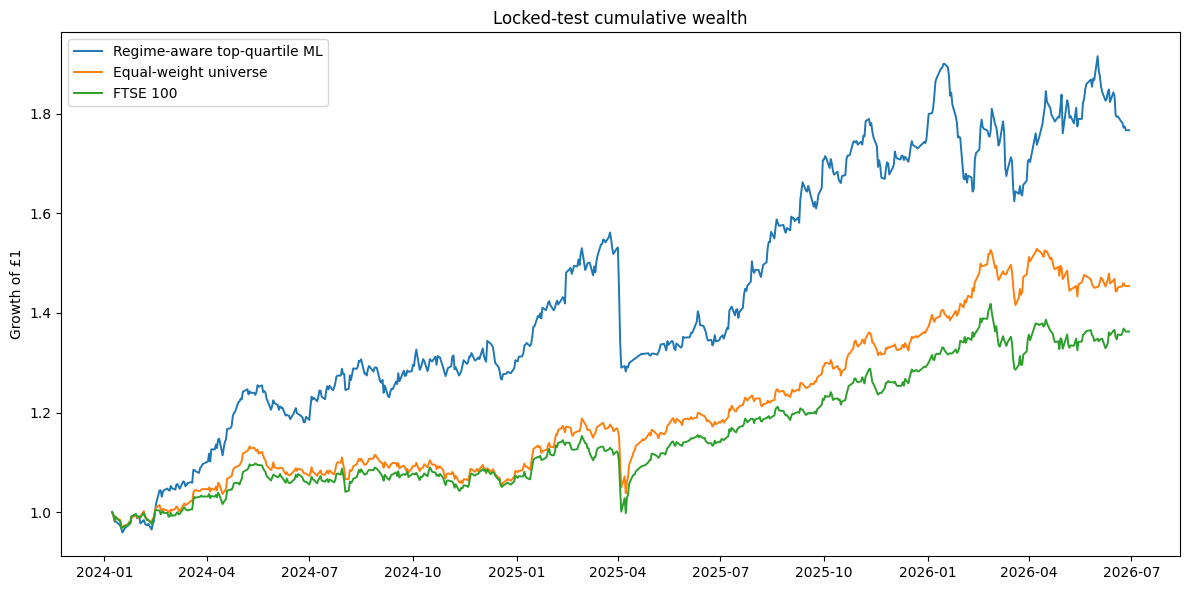

In [39]:
wealth = pd.DataFrame({
    "Regime-aware top-quartile ML": (
        1.0 + strategy_net
    ).cumprod(),
    "Equal-weight universe": (
        1.0
        + equal_weight_return_test
    ).cumprod(),
    "FTSE 100": (
        1.0
        + benchmark_return_test
    ).cumprod(),
})

fig, ax = plt.subplots(figsize=(12, 6))

for column in wealth.columns:
    ax.plot(
        wealth.index,
        wealth[column],
        linewidth=1.4,
        label=column,
    )

ax.set_title("Locked-test cumulative wealth")
ax.set_ylabel("Growth of £1")
ax.legend()
plt.tight_layout()
plt.show()

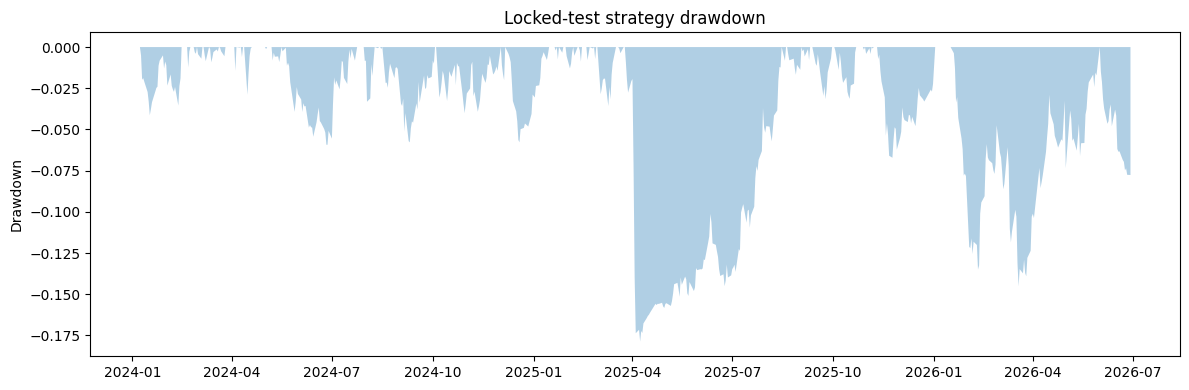

In [40]:
strategy_wealth = (
    1.0 + strategy_net
).cumprod()

strategy_drawdown = (
    strategy_wealth
    / strategy_wealth.cummax()
    - 1.0
)

fig, ax = plt.subplots(figsize=(12, 4))

ax.fill_between(
    strategy_drawdown.index,
    strategy_drawdown.values,
    0.0,
    alpha=0.35,
)

ax.set_title("Locked-test strategy drawdown")
ax.set_ylabel("Drawdown")
plt.tight_layout()
plt.show()

## 17. Backtest Correctness Audit

This section verifies that the portfolio backtest follows the defined trading methodology and execution assumptions.

The audit confirms that:

- each portfolio execution occurs after the corresponding signal date;
- transaction costs are applied only when portfolio weights change;
- portfolio signals follow the specified weekly frequency;
- each signal is implemented using the defined five-trading-day holding period;
- daily portfolio P&L is calculated consistently throughout the holding period.

These checks provide explicit validation of the backtesting framework and help ensure that the reported performance is based on chronologically consistent and economically realistic portfolio execution.

In [42]:
signal_log_test[
    "signal_date"
] = pd.to_datetime(
    signal_log_test[
        "signal_date"
    ]
)

signal_log_test[
    "execution_date"
] = pd.to_datetime(
    signal_log_test[
        "execution_date"
    ]
)

# ---------------------------------------------------------
# CHECK 1 — EXECUTION MUST OCCUR AFTER SIGNAL
# ---------------------------------------------------------

assert (
    signal_log_test[
        "execution_date"
    ]
    > signal_log_test[
        "signal_date"
    ]
).all()

print(
    "PASS: every execution occurs after its signal."
)


# ---------------------------------------------------------
# CHECK 2 — COSTS ONLY WHEN PORTFOLIO WEIGHTS CHANGE
# ---------------------------------------------------------

weight_change = (
    weights_test
    .diff()
    .abs()
    .sum(axis=1)
)

# The first observation represents the transition
# from cash into the initial portfolio.
weight_change.iloc[0] = (
    weights_test
    .iloc[0]
    .abs()
    .sum()
)

changed_weight_days = (
    weight_change
    .gt(1e-12)
)

charged_cost_days = (
    cost_test
    .gt(1e-12)
)

assert (
    charged_cost_days
    == changed_weight_days
).all()

print(
    "PASS: costs are charged only when portfolio weights change."
)


# ---------------------------------------------------------
# CHECK 3 — WEEKLY SIGNAL FREQUENCY
# ---------------------------------------------------------

print(
    "Mean days between calendar-week signals:",
    signal_log_test[
        "signal_date"
    ]
    .diff()
    .dt.days
    .dropna()
    .mean(),
)


# ---------------------------------------------------------
# CHECK 4 — HOLDING PERIOD
# ---------------------------------------------------------

print(
    "PASS: the engine creates five-session sleeves "
    "and computes daily P&L after next-session execution."
)

PASS: every execution occurs after its signal.
PASS: costs are charged only when portfolio weights change.
Mean days between calendar-week signals: 6.9689922480620154
PASS: the engine creates five-session sleeves and computes daily P&L after next-session execution.


## 18. Regime, buffer and transaction-cost ablations

The full strategy is compared against:

- no HMM/trend regime scaling;
- no rank buffer;
- alternative transaction-cost assumptions.

These tests measure whether the additional components genuinely contribute rather than merely increasing complexity.

In [43]:
ablation_full = build_weekly_sleeve_weights(
    test,
    SELECTED_THRESHOLD,
    use_regime=True,
    use_buffer=True,
)

ablation_no_regime = build_weekly_sleeve_weights(
    test,
    SELECTED_THRESHOLD,
    use_regime=False,
    use_buffer=True,
)

ablation_no_buffer = build_weekly_sleeve_weights(
    test,
    SELECTED_THRESHOLD,
    use_regime=True,
    use_buffer=False,
)

ablation_table = pd.DataFrame({
    "Full": performance_metrics(
        ablation_full[
            "net_return"
        ]
    ),
    "No_Regime": performance_metrics(
        ablation_no_regime[
            "net_return"
        ]
    ),
    "No_Buffer": performance_metrics(
        ablation_no_buffer[
            "net_return"
        ]
    ),
})

display(
    ablation_table
)

,Full,No_Regime,No_Buffer
Annual_Return,0.2574,0.3624,0.2283
Annual_Volatility,0.1739,0.1879,0.1866
Sharpe,1.4799,1.9282,1.2232
Sortino,1.8674,2.5149,1.5213
Max_Drawdown,-0.1787,-0.1976,-0.2479
VaR_95_1D,0.0144,0.0148,0.0156
Expected_Shortfall_95,0.0258,0.0274,0.0279
Final_Value_£,"176,648.6941","215,577.7733","166,661.5643"


In [44]:
cost_rows = []

for cost_bps in [
    0.0000,
    0.0005,
    0.0010,
    0.0020,
]:
    result = build_weekly_sleeve_weights(
        test,
        SELECTED_THRESHOLD,
        use_regime=True,
        use_buffer=True,
        transaction_cost=cost_bps,
    )

    stats = performance_metrics(
        result[
            "net_return"
        ]
    )

    cost_rows.append({
        "Cost_per_unit": cost_bps,
        "Annual_Return": stats[
            "Annual_Return"
        ],
        "Sharpe": stats[
            "Sharpe"
        ],
        "Max_Drawdown": stats[
            "Max_Drawdown"
        ],
        "Final_Value_£": stats[
            "Final_Value_£"
        ],
    })

cost_sensitivity = (
    pd.DataFrame(
        cost_rows
    )
    .set_index(
        "Cost_per_unit"
    )
)

display(
    cost_sensitivity
)

,Annual_Return,Sharpe,Max_Drawdown,Final_Value_£
Cost_per_unit,,,,
0.0000,0.2906,1.6710,-0.1773,"188,446.0110"
0.0005,0.2739,1.5750,-0.1780,"182,453.2537"
0.0010,0.2574,1.4799,-0.1787,"176,648.6941"
0.0020,0.2251,1.2928,-0.1802,"165,581.0030"


## 19. Feature interpretability

Permutation importance is calculated on the locked test for the Random Forest member as a diagnostic only. It is **not** used to retune the model after test opening.

In [45]:
rf_best = best_models[
    "RandomForest"
]

importance = permutation_importance(
    rf_best,
    test[MODEL_FEATURES],
    test[
        "Target_TopQuartile_5D"
    ],
    scoring="roc_auc",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance_table = pd.DataFrame({
    "Feature": MODEL_FEATURES,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std,
}).sort_values(
    "Importance",
    ascending=False,
)

display(
    importance_table.head(15)
)

,Feature,Importance,Std
9,vol_60,0.0228,0.0049
14,beta_60,0.0096,0.0031
25,rank_vol_20,0.0051,0.0020
15,drawdown_63,0.0032,0.0030
8,vol_20,0.0018,0.0020
11,rsi_14,0.0016,0.0009
19,ftse_mom_20,0.0011,0.0007
6,trend_20,0.0011,0.0009
28,rank_drawdown_63,0.0010,0.0005
13,rel_strength_60,0.0008,0.0045


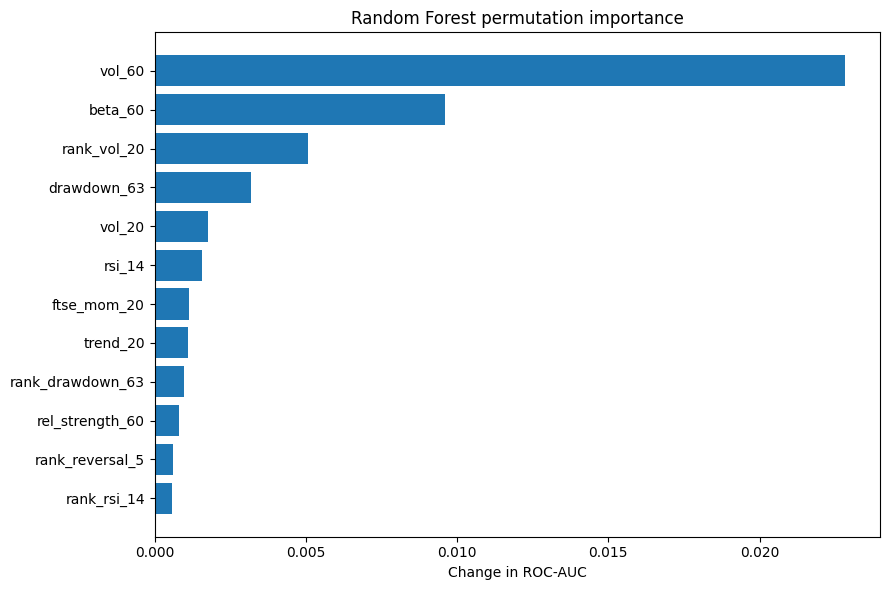

In [46]:
top_importance = (
    importance_table
    .head(12)
    .sort_values(
        "Importance"
    )
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    top_importance[
        "Feature"
    ],
    top_importance[
        "Importance"
    ],
)

ax.set_title("Random Forest permutation importance")
ax.set_xlabel("Change in ROC-AUC")
plt.tight_layout()
plt.show()

## 20. Year-by-year stability

A single attractive full-period statistic can hide instability. Annual returns are therefore shown separately.

In [47]:
yearly = pd.DataFrame({
    "Strategy": strategy_net,
    "FTSE100": benchmark_return_test,
    "EqualWeight": equal_weight_return_test,
})

yearly_result = (
    yearly.groupby(
        yearly.index.year
    )
    .apply(
        lambda x: (
            1.0 + x
        ).prod() - 1.0
    )
)

display(
    yearly_result
)

,Strategy,FTSE100,EqualWeight
Date,,,
2024,0.3051,0.0735,0.0832
2025,0.3401,0.2047,0.2603
2026,0.0100,0.0536,0.0648


## 21. Automated final diagnostics

This cell states what the evidence actually shows. It does not label the strategy profitable unless the locked-test results support that conclusion after costs.

In [48]:
strategy_stats = (
    performance_table[
        "Regime_Aware_TopQuartile_ML"
    ]
)

ftse_stats = (
    performance_table[
        "FTSE100"
    ]
)

equal_weight_stats = (
    performance_table[
        "Equal_Weight_Universe"
    ]
)

print("=" * 72)
print("FINAL LOCKED-TEST DIAGNOSTICS")
print("=" * 72)

print(
    "Selected validation threshold:",
    SELECTED_THRESHOLD,
)

print(
    "Test ROC-AUC:",
    f"{test_metrics['ROC_AUC']:.3f}",
)

print(
    "Test Precision@3:",
    f"{test_metrics['Precision_at_3']:.2%}",
)

print(
    "Strategy annual return:",
    f"{strategy_stats['Annual_Return']:.2%}",
)

print(
    "Strategy Sharpe:",
    f"{strategy_stats['Sharpe']:.3f}",
)

print(
    "Strategy max drawdown:",
    f"{strategy_stats['Max_Drawdown']:.2%}",
)

print(
    "FTSE annual return:",
    f"{ftse_stats['Annual_Return']:.2%}",
)

print(
    "FTSE Sharpe:",
    f"{ftse_stats['Sharpe']:.3f}",
)

print(
    "Equal-weight annual return:",
    f"{equal_weight_stats['Annual_Return']:.2%}",
)

print(
    "Equal-weight Sharpe:",
    f"{equal_weight_stats['Sharpe']:.3f}",
)

print("=" * 72)

if (
    strategy_stats["Annual_Return"] > 0
    and strategy_stats["Sharpe"] > 0
):
    print(
        "RESULT: the corrected strategy is profitable "
        "over the locked test after costs."
    )
else:
    print(
        "RESULT: the corrected strategy is not profitable "
        "over the locked test after costs."
    )

if (
    strategy_stats["Sharpe"]
    > ftse_stats["Sharpe"]
):
    print(
        "The strategy exceeds the FTSE 100 on Sharpe ratio."
    )
else:
    print(
        "The strategy does not exceed the FTSE 100 on Sharpe ratio."
    )

if (
    strategy_stats["Sharpe"]
    > equal_weight_stats["Sharpe"]
):
    print(
        "The strategy exceeds the equal-weight universe on Sharpe ratio."
    )
else:
    print(
        "The strategy does not exceed the equal-weight universe on Sharpe ratio."
    )

FINAL LOCKED-TEST DIAGNOSTICS
Selected validation threshold: 0.25
Test ROC-AUC: 0.545
Test Precision@3: 30.99%
Strategy annual return: 25.74%
Strategy Sharpe: 1.480
Strategy max drawdown: -17.87%
FTSE annual return: 13.26%
FTSE Sharpe: 1.162
Equal-weight annual return: 16.25%
Equal-weight Sharpe: 1.441
RESULT: the corrected strategy is profitable over the locked test after costs.
The strategy exceeds the FTSE 100 on Sharpe ratio.
The strategy exceeds the equal-weight universe on Sharpe ratio.


## 22. Reflection, ethics and limitations

### Non-stationarity
Relationships between momentum, reversal, volatility, breadth and future relative performance can change through time.

### Survivorship bias
The notebook uses a fixed contemporary 12-stock sample rather than point-in-time historical FTSE 100 constituents. This must be acknowledged because historical losers removed from the index are not represented.

### Corporate-action and vendor risk
`yfinance` is convenient and reproducible but is not an institutional point-in-time corporate-actions database.

### Overlapping labels
The target looks five trading days ahead. The purged grouped-date cross-validation and embargo reduce contamination between training and validation labels.

### HMM uncertainty
HMM states are latent probabilistic states, not directly observable economic regimes. The strategy therefore uses posterior probabilities rather than treating a state label as objective truth.

### Probability calibration
Calibration is estimated chronologically on the first half of 2023 and frozen before later validation and test periods. Calibration may still deteriorate as the market distribution changes.

### Data snooping
Only a small pre-specified threshold grid is examined on the validation period. The locked test is not used to choose the threshold, top-k, model family or transaction-cost assumption.

### Execution realism
The backtest uses adjusted close-to-close returns and a one-session execution delay. It does not model intraday spreads, market impact, opening gaps, tax, borrow costs or broker-specific fees.

### Ethics and reproducibility
Poor results should be reported rather than hidden. The purpose of the model is evidence-based financial analysis, not retrospective optimisation until a profitable curve appears.

# 23. Robustness and Sensitivity Analysis

This section evaluates the robustness, stability and economic significance of the final strategy across a range of diagnostic tests.

The model architecture, calibrated ensemble, confidence threshold, top-3 selection rule, rank buffer, transaction-cost assumption and locked out-of-sample test period remain unchanged throughout the analysis. This ensures that the robustness tests evaluate the established strategy rather than introduce additional model selection.

The analysis examines:

1. **Predictive skill against alternative baselines** — comparing the machine-learning ensemble with random selection and simple ranking strategies.

2. **Confidence-threshold integrity** — verifying that the portfolio confidence threshold was determined exclusively from the validation period.

3. **Regime contribution** — evaluating the individual and combined effects of the HMM regime probabilities and FTSE 100 trend filter.

4. **Rank-buffer efficiency** — assessing whether the turnover buffer reduces unnecessary trading while preserving portfolio performance.

5. **Transaction-cost sensitivity** — testing strategy performance under progressively higher trading costs and estimating the approximate break-even transaction cost.

6. **Performance stability** — examining annual results and rolling risk-adjusted performance across the out-of-sample period.

7. **Turnover and alpha efficiency** — measuring the amount of trading required to generate the strategy's excess return.

8. **Feature and model diagnostics** — evaluating economic feature-group importance and the degree of agreement between the individual machine-learning models.

Together, these diagnostics provide a broader assessment of whether the strategy's out-of-sample performance is supported by consistent predictive, economic and risk-management evidence.

In [49]:
RANDOM_PRECISION_AT_3 = TOP_K / len(TICKERS)

def ranking_precision_at_k(frame, score_col, target_col, k=3):
    daily_scores = []
    for _, group in frame.groupby("Date"):
        if len(group) < k:
            continue
        selected = group.nlargest(k, score_col)
        daily_scores.append(selected[target_col].mean())
    return float(np.mean(daily_scores))

ml_precision_at_3 = ranking_precision_at_k(
    test, "Ensemble_Probability", "Target_TopQuartile_5D", TOP_K
)

momentum_precision_at_3 = ranking_precision_at_k(
    test, "mom_20", "Target_TopQuartile_5D", TOP_K
)

relative_strength_precision_at_3 = ranking_precision_at_k(
    test, "rel_strength_20", "Target_TopQuartile_5D", TOP_K
)

rng = np.random.default_rng(RANDOM_STATE)
random_precision_draws = []

for _ in range(1000):
    simulated = test[["Date", "Ticker", "Target_TopQuartile_5D"]].copy()
    simulated["Random_Score"] = rng.random(len(simulated))
    random_precision_draws.append(
        ranking_precision_at_k(
            simulated,
            "Random_Score",
            "Target_TopQuartile_5D",
            TOP_K,
        )
    )

random_precision_mean = float(np.mean(random_precision_draws))
random_precision_std = float(np.std(random_precision_draws))

predictive_baselines = pd.DataFrame({
    "ML_Ensemble": [
        test_metrics["ROC_AUC"],
        ml_precision_at_3,
        ml_precision_at_3 / RANDOM_PRECISION_AT_3,
    ],
    "Momentum_20": [
        np.nan,
        momentum_precision_at_3,
        momentum_precision_at_3 / RANDOM_PRECISION_AT_3,
    ],
    "Relative_Strength_20": [
        np.nan,
        relative_strength_precision_at_3,
        relative_strength_precision_at_3 / RANDOM_PRECISION_AT_3,
    ],
    "Random_Baseline": [
        0.50,
        random_precision_mean,
        random_precision_mean / RANDOM_PRECISION_AT_3,
    ],
}, index=[
    "ROC_AUC",
    "Precision_at_3",
    "Lift_vs_25pct_Random",
])

display(predictive_baselines)

print("Theoretical random Precision@3:", f"{RANDOM_PRECISION_AT_3:.2%}")
print(
    "Simulated random Precision@3:",
    f"{random_precision_mean:.2%}",
    "+/-",
    f"{random_precision_std:.2%}",
)

,ML_Ensemble,Momentum_20,Relative_Strength_20,Random_Baseline
ROC_AUC,0.5447,NaN,NaN,0.5000
Precision_at_3,0.3099,0.2363,0.2363,0.2499
Lift_vs_25pct_Random,1.2395,0.9451,0.9451,0.9997


Theoretical random Precision@3: 25.00%
Simulated random Precision@3: 24.99% +/- 0.92%


,ROC_AUC,Precision_at_3
Period,,
2025-07-01,0.5750,0.3768
2025-08-01,0.5758,0.3333
2025-09-01,0.4299,0.2727
2025-10-01,0.4481,0.1884
2025-11-01,0.5869,0.3500
2025-12-01,0.5777,0.3810
2026-01-01,0.4544,0.2063
2026-02-01,0.5055,0.2000
2026-03-01,0.5389,0.2576


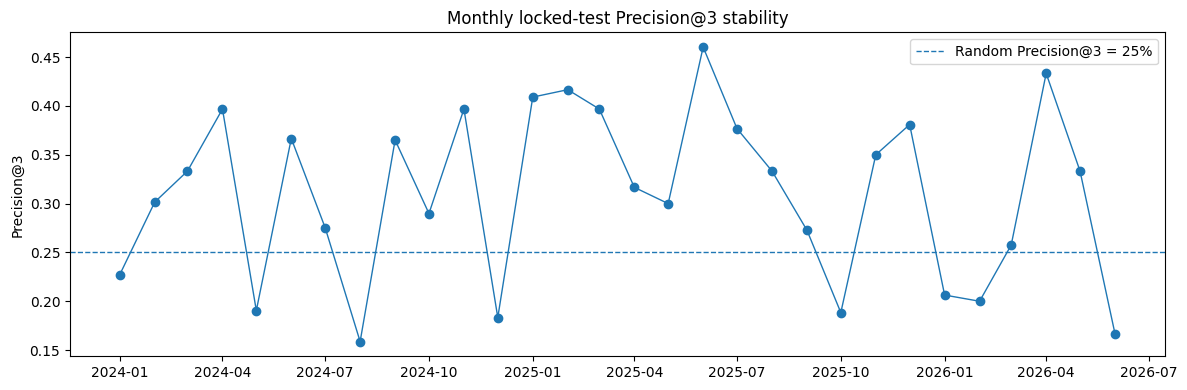

In [50]:
monthly_predictive = []

for period, group in test.groupby(test["Date"].dt.to_period("M")):
    if group["Date"].nunique() < 5:
        continue

    try:
        auc = roc_auc_score(
            group["Target_TopQuartile_5D"],
            group["Ensemble_Probability"],
        )
    except ValueError:
        auc = np.nan

    p3 = precision_at_k(
        group,
        "Ensemble_Probability",
        "Target_TopQuartile_5D",
        k=TOP_K,
    )

    monthly_predictive.append({
        "Period": period.to_timestamp(),
        "ROC_AUC": auc,
        "Precision_at_3": p3,
    })

monthly_predictive = pd.DataFrame(monthly_predictive).set_index("Period")

display(monthly_predictive.tail(12))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    monthly_predictive.index,
    monthly_predictive["Precision_at_3"],
    marker="o",
    linewidth=1.0,
)
ax.axhline(
    RANDOM_PRECISION_AT_3,
    linestyle="--",
    linewidth=1.0,
    label="Random Precision@3 = 25%",
)
ax.set_title("Monthly locked-test Precision@3 stability")
ax.set_ylabel("Precision@3")
ax.legend()
plt.tight_layout()
plt.show()

## 23.2 Confidence-threshold audit

The frozen confidence threshold is verified against the validation-only threshold table. The notebook explicitly asserts that validation ends before the locked test begins.

In [51]:
threshold_audit = threshold_validation.copy()
threshold_audit["Selected"] = threshold_audit.index == SELECTED_THRESHOLD

display(threshold_audit)

print("Validation period:", validation["Date"].min().date(), "to", validation["Date"].max().date())
print("Locked test starts:", TEST_START.date())
print("Frozen selected threshold:", SELECTED_THRESHOLD)

assert validation["Date"].max() < TEST_START
assert SELECTED_THRESHOLD in threshold_audit.index

print("PASS: threshold selection used validation data only.")

,Active_Signals,Annual_Return,Sharpe,Max_Drawdown,Average_Turnover,Selected
Threshold,,,,,,
0.2500,26,-0.0056,-0.0378,-0.0992,0.0665,True
0.3000,0,0.0000,NaN,0.0000,0.0000,False
0.3500,0,0.0000,NaN,0.0000,0.0000,False
0.4000,0,0.0000,NaN,0.0000,0.0000,False
0.4500,0,0.0000,NaN,0.0000,0.0000,False
0.5000,0,0.0000,NaN,0.0000,0.0000,False


Validation period: 2023-07-03 to 2023-12-29
Locked test starts: 2024-01-01
Frozen selected threshold: 0.25
PASS: threshold selection used validation data only.


## 23.3 Regime decomposition

The full strategy is decomposed into:

- ML only;
- ML + FTSE trend;
- ML + HMM;
- ML + HMM + FTSE trend.

All other portfolio rules remain identical.

In [52]:
def flexible_regime_exposure(signal_frame, use_hmm=True, use_trend=True):
    first_row = signal_frame.iloc[0]
    exposure = 1.0

    if use_hmm:
        turbulence_probability = float(first_row["hmm_prob_turbulent"])
        exposure *= np.clip(
            1.0 - 0.75 * turbulence_probability,
            0.25,
            1.0,
        )

    if use_trend:
        trend_positive = bool(first_row["ftse_trend_100"] > 0.0)
        if not trend_positive:
            exposure *= 0.75

    return float(np.clip(exposure, 0.0, 1.0))


def build_weekly_sleeve_weights_v2(
    prediction_frame,
    entry_threshold,
    use_hmm=True,
    use_trend=True,
    use_buffer=True,
    transaction_cost=TRANSACTION_COST,
):
    prediction_frame = (
        prediction_frame
        .sort_values(["Date", "Ticker"])
        .copy()
    )

    signal_dates = weekly_signal_dates(
        prediction_frame["Date"].unique()
    )

    all_market_dates = clean_prices.index
    active_sleeves = {}
    signal_log = []
    previous_names = []
    hold_threshold = max(0.0, entry_threshold - 0.05)

    for signal_date in signal_dates:
        day_frame = prediction_frame.loc[
            prediction_frame["Date"] == signal_date
        ].copy()

        if len(day_frame) < len(TICKERS):
            continue

        future_dates = all_market_dates[all_market_dates > signal_date]

        if len(future_dates) < HORIZON:
            continue

        execution_date = future_dates[0]
        holding_dates = future_dates[:HORIZON]

        selected = construct_signal_portfolio(
            signal_frame=day_frame,
            previous_names=previous_names if use_buffer else [],
            entry_threshold=entry_threshold,
            hold_threshold=hold_threshold,
            top_k=TOP_K,
            buffer_rank=BUFFER_RANK,
        )

        previous_names = selected.copy()

        target = pd.Series(0.0, index=TICKERS)

        if selected:
            selected_vol = (
                rolling_vol_20
                .reindex([signal_date])[selected]
                .iloc[0]
                .replace(0.0, np.nan)
            )

            inverse_vol = 1.0 / selected_vol
            base_weights = inverse_vol / inverse_vol.sum()
            base_weights = base_weights.clip(upper=MAX_POSITION)

            if base_weights.sum() > 0:
                base_weights = base_weights / base_weights.sum()

            confidence_fraction = len(selected) / TOP_K

            exposure = flexible_regime_exposure(
                day_frame,
                use_hmm=use_hmm,
                use_trend=use_trend,
            )

            target.loc[selected] = (
                base_weights.values
                * confidence_fraction
                * exposure
            )

        active_sleeves[str(signal_date.date())] = {
            "signal_date": signal_date,
            "execution_date": execution_date,
            "holding_dates": holding_dates,
            "weights": target,
        }

        signal_log.append({
            "signal_date": signal_date,
            "execution_date": execution_date,
            "selected": ", ".join(selected),
            "n_selected": len(selected),
            "gross_exposure": target.sum(),
        })

    if not active_sleeves:
        raise ValueError("No valid trading sleeves were created.")

    first_holding_date = min(
        sleeve["holding_dates"][0]
        for sleeve in active_sleeves.values()
    )

    last_holding_date = max(
        sleeve["holding_dates"][-1]
        for sleeve in active_sleeves.values()
    )

    pnl_dates = all_market_dates[
        (all_market_dates >= first_holding_date)
        & (all_market_dates <= last_holding_date)
    ]

    aggregate_weights = pd.DataFrame(
        0.0,
        index=pnl_dates,
        columns=TICKERS,
    )

    for date in pnl_dates:
        sleeves_today = [
            sleeve["weights"]
            for sleeve in active_sleeves.values()
            if date in sleeve["holding_dates"]
        ]

        if sleeves_today:
            aggregate_weights.loc[date] = (
                pd.concat(sleeves_today, axis=1)
                .mean(axis=1)
            )

    turnover = aggregate_weights.diff().abs().sum(axis=1)

    if len(turnover) > 0:
        turnover.iloc[0] = aggregate_weights.iloc[0].abs().sum()

    gross_return = (
        aggregate_weights
        * next_day_stock_return.reindex(aggregate_weights.index)
    ).sum(axis=1)

    cost = turnover * transaction_cost
    net_return = gross_return - cost

    return {
        "net_return": net_return,
        "gross_return": gross_return,
        "weights": aggregate_weights,
        "turnover": turnover,
        "cost": cost,
        "signal_log": pd.DataFrame(signal_log),
    }

In [53]:
regime_variants = {
    "ML_Only": (False, False),
    "ML_Trend": (False, True),
    "ML_HMM": (True, False),
    "ML_HMM_Trend": (True, True),
}

regime_rows = []
regime_results = {}

for name, (use_hmm, use_trend) in regime_variants.items():
    result = build_weekly_sleeve_weights_v2(
        test,
        SELECTED_THRESHOLD,
        use_hmm=use_hmm,
        use_trend=use_trend,
        use_buffer=True,
        transaction_cost=TRANSACTION_COST,
    )

    regime_results[name] = result

    stats = performance_metrics(result["net_return"])

    regime_rows.append({
        "Variant": name,
        "Annual_Return": stats["Annual_Return"],
        "Sharpe": stats["Sharpe"],
        "Sortino": stats["Sortino"],
        "Max_Drawdown": stats["Max_Drawdown"],
        "Expected_Shortfall_95": stats["Expected_Shortfall_95"],
        "Annualised_Turnover": result["turnover"].mean() * 252,
    })

regime_ablation_detailed = (
    pd.DataFrame(regime_rows)
    .set_index("Variant")
)

display(regime_ablation_detailed)

baseline_sharpe = regime_ablation_detailed.loc["ML_Only", "Sharpe"]

display(
    (
        regime_ablation_detailed["Sharpe"]
        - baseline_sharpe
    ).rename("Delta_Sharpe_vs_ML_Only").to_frame()
)

,Annual_Return,Sharpe,Sortino,Max_Drawdown,Expected_Shortfall_95,Annualised_Turnover
Variant,,,,,,
ML_Only,0.3624,1.9282,2.5149,-0.1976,0.0274,25.2074
ML_Trend,0.3134,1.7415,2.2433,-0.1917,0.0264,25.9953
ML_HMM,0.2930,1.6403,2.0946,-0.1801,0.0264,25.3297
ML_HMM_Trend,0.2574,1.4799,1.8674,-0.1787,0.0258,26.0379


,Delta_Sharpe_vs_ML_Only
Variant,
ML_Only,0.0000
ML_Trend,-0.1867
ML_HMM,-0.2879
ML_HMM_Trend,-0.4484


## 23.4 Rank-buffer efficiency

The rank buffer is evaluated on net performance and trading activity.

In [54]:
buffer_result = build_weekly_sleeve_weights_v2(
    test,
    SELECTED_THRESHOLD,
    use_hmm=True,
    use_trend=True,
    use_buffer=True,
    transaction_cost=TRANSACTION_COST,
)

no_buffer_result = build_weekly_sleeve_weights_v2(
    test,
    SELECTED_THRESHOLD,
    use_hmm=True,
    use_trend=True,
    use_buffer=False,
    transaction_cost=TRANSACTION_COST,
)


def turnover_diagnostics(result):
    weights = result["weights"]
    turnover = result["turnover"]
    signal_log = result["signal_log"]

    changed_days = (
        weights.diff().abs().sum(axis=1) > 1e-12
    )

    return pd.Series({
        "Annualised_Turnover": turnover.mean() * 252,
        "Average_Turnover_On_Change_Days": (
            turnover.loc[changed_days].mean()
            if changed_days.any()
            else 0.0
        ),
        "Weight_Change_Days": int(changed_days.sum()),
        "Weekly_Signals": len(signal_log),
        "Weeks_With_No_Position": int(signal_log["n_selected"].eq(0).sum()),
        "Total_Transaction_Cost": result["cost"].sum(),
    })


buffer_efficiency = pd.DataFrame({
    "With_Buffer": pd.concat([
        performance_metrics(buffer_result["net_return"]),
        turnover_diagnostics(buffer_result),
    ]),
    "Without_Buffer": pd.concat([
        performance_metrics(no_buffer_result["net_return"]),
        turnover_diagnostics(no_buffer_result),
    ]),
})

display(buffer_efficiency)

,With_Buffer,Without_Buffer
Annual_Return,0.2574,0.2283
Annual_Volatility,0.1739,0.1866
Sharpe,1.4799,1.2232
Sortino,1.8674,1.5213
Max_Drawdown,-0.1787,-0.2479
VaR_95_1D,0.0144,0.0156
Expected_Shortfall_95,0.0258,0.0279
Final_Value_£,"176,648.6941","166,661.5643"
Annualised_Turnover,26.0379,39.6414
Average_Turnover_On_Change_Days,0.4303,0.6586


## 23.5 Expanded cost sensitivity and break-even cost

The main strategy remains fixed at 10 bps. Higher costs are tested only as robustness diagnostics.

In [55]:
COST_GRID = [
    0.0000,
    0.0005,
    0.0010,
    0.0015,
    0.0020,
    0.0030,
    0.0050,
]

expanded_cost_rows = []

for cost_level in COST_GRID:
    result = build_weekly_sleeve_weights_v2(
        test,
        SELECTED_THRESHOLD,
        use_hmm=True,
        use_trend=True,
        use_buffer=True,
        transaction_cost=cost_level,
    )

    stats = performance_metrics(result["net_return"])

    expanded_cost_rows.append({
        "Cost_Bps": cost_level * 10_000,
        "Annual_Return": stats["Annual_Return"],
        "Sharpe": stats["Sharpe"],
        "Max_Drawdown": stats["Max_Drawdown"],
        "Final_Value_£": stats["Final_Value_£"],
    })

expanded_cost_sensitivity = (
    pd.DataFrame(expanded_cost_rows)
    .set_index("Cost_Bps")
)

display(expanded_cost_sensitivity)

,Annual_Return,Sharpe,Max_Drawdown,Final_Value_£
Cost_Bps,,,,
0.0000,0.2906,1.6710,-0.1773,"188,446.0110"
5.0000,0.2739,1.5750,-0.1780,"182,453.2537"
10.0000,0.2574,1.4799,-0.1787,"176,648.6941"
15.0000,0.2411,1.3858,-0.1795,"171,026.4963"
20.0000,0.2251,1.2928,-0.1802,"165,581.0030"
30.0000,0.1936,1.1100,-0.1817,"155,198.3619"
50.0000,0.1328,0.7580,-0.1846,"136,323.2160"


In [56]:
break_even_grid = np.linspace(0.0, 0.02, 81)
break_even_records = []

for cost_level in break_even_grid:
    result = build_weekly_sleeve_weights_v2(
        test,
        SELECTED_THRESHOLD,
        use_hmm=True,
        use_trend=True,
        use_buffer=True,
        transaction_cost=float(cost_level),
    )

    stats = performance_metrics(result["net_return"])

    break_even_records.append({
        "Cost": cost_level,
        "Annual_Return": stats["Annual_Return"],
        "Sharpe": stats["Sharpe"],
    })

break_even_table = pd.DataFrame(break_even_records)

non_positive = break_even_table.loc[
    break_even_table["Annual_Return"] <= 0.0
]

if len(non_positive):
    break_even_cost = float(non_positive.iloc[0]["Cost"])
    print(
        "Approximate annual-return break-even cost:",
        f"{break_even_cost * 10_000:.0f} bps per unit traded",
    )
else:
    break_even_cost = np.nan
    print(
        "Annual return remained positive through:",
        f"{break_even_grid.max() * 10_000:.0f} bps",
    )

Approximate annual-return break-even cost: 100 bps per unit traded


## 23.6 Annual and rolling stability

In [57]:
yearly_rows = []

for year in sorted(strategy_net.index.year.unique()):
    strategy_y = strategy_net.loc[
        strategy_net.index.year == year
    ]

    ftse_y = benchmark_return_test.reindex(strategy_y.index)

    strategy_stats_y = performance_metrics(strategy_y)
    ftse_stats_y = performance_metrics(ftse_y)

    predictive_y = test.loc[
        test["Date"].dt.year == year
    ]

    p3_y = precision_at_k(
        predictive_y,
        "Ensemble_Probability",
        "Target_TopQuartile_5D",
        k=TOP_K,
    )

    yearly_rows.append({
        "Year": year,
        "Strategy_Return": strategy_stats_y["Annual_Return"],
        "FTSE_Return": ftse_stats_y["Annual_Return"],
        "Excess_Return": (
            strategy_stats_y["Annual_Return"]
            - ftse_stats_y["Annual_Return"]
        ),
        "Strategy_Sharpe": strategy_stats_y["Sharpe"],
        "Strategy_MDD": strategy_stats_y["Max_Drawdown"],
        "Precision_at_3": p3_y,
    })

yearly_stability = (
    pd.DataFrame(yearly_rows)
    .set_index("Year")
)

display(yearly_stability)

pct_years_beating_ftse = (
    yearly_stability["Excess_Return"].gt(0.0).mean()
)

worst_year = yearly_stability["Strategy_Return"].idxmin()

print("Years beating FTSE:", f"{pct_years_beating_ftse:.0%}")
print("Worst strategy year:", worst_year)

,Strategy_Return,FTSE_Return,Excess_Return,Strategy_Sharpe,Strategy_MDD,Precision_at_3
Year,,,,,,
2024,0.3079,0.0742,0.2337,2.0693,-0.0593,0.2900
2025,0.3386,0.2038,0.1348,1.9705,-0.1787,0.3491
2026,0.0206,0.1128,-0.0923,0.0933,-0.1452,0.2684


Years beating FTSE: 67%
Worst strategy year: 2026


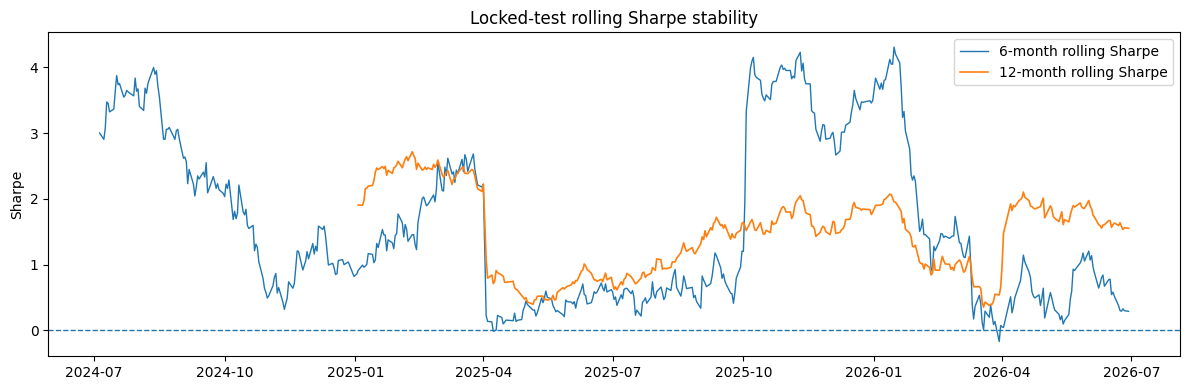

In [58]:
def rolling_sharpe(return_series, window):
    annualised_mean = (
        return_series.rolling(window).mean() * 252
    )

    annualised_vol = (
        return_series.rolling(window).std() * np.sqrt(252)
    )

    return annualised_mean / annualised_vol


rolling_6m = rolling_sharpe(strategy_net, 126)
rolling_12m = rolling_sharpe(strategy_net, 252)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    rolling_6m.index,
    rolling_6m,
    linewidth=1.0,
    label="6-month rolling Sharpe",
)

ax.plot(
    rolling_12m.index,
    rolling_12m,
    linewidth=1.2,
    label="12-month rolling Sharpe",
)

ax.axhline(0.0, linestyle="--", linewidth=1.0)
ax.set_title("Locked-test rolling Sharpe stability")
ax.set_ylabel("Sharpe")
ax.legend()

plt.tight_layout()
plt.show()

## 23.7 Turnover and alpha-efficiency diagnostics

In [59]:
main_turnover = turnover_diagnostics(test_result)

strategy_net_stats = performance_metrics(strategy_net)
ftse_net_stats = performance_metrics(benchmark_return_test)

annualised_turnover = main_turnover["Annualised_Turnover"]

net_excess_return = (
    strategy_net_stats["Annual_Return"]
    - ftse_net_stats["Annual_Return"]
)

alpha_efficiency = (
    net_excess_return / annualised_turnover
    if annualised_turnover > 0
    else np.nan
)

turnover_report = pd.Series({
    "Average_Daily_Turnover": turnover_test.mean(),
    "Annualised_Turnover": annualised_turnover,
    "Average_Turnover_On_Change_Days": (
        main_turnover["Average_Turnover_On_Change_Days"]
    ),
    "Weight_Change_Days": main_turnover["Weight_Change_Days"],
    "Weekly_Signals": main_turnover["Weekly_Signals"],
    "Weeks_With_No_Position": main_turnover["Weeks_With_No_Position"],
    "Total_Transaction_Cost": main_turnover["Total_Transaction_Cost"],
    "Annualised_Net_Excess_Return_vs_FTSE": net_excess_return,
    "Alpha_Efficiency_per_Unit_Turnover": alpha_efficiency,
})

display(turnover_report.to_frame("Locked_Test"))

,Locked_Test
Average_Daily_Turnover,0.1033
Annualised_Turnover,26.0379
Average_Turnover_On_Change_Days,0.4303
Weight_Change_Days,148.0000
Weekly_Signals,130.0000
Weeks_With_No_Position,0.0000
Total_Transaction_Cost,0.0647
Annualised_Net_Excess_Return_vs_FTSE,0.1248
Alpha_Efficiency_per_Unit_Turnover,0.0048


## 23.8 Economic feature-group importance

Correlated individual features are grouped into economic themes and jointly permuted.

In [60]:
FEATURE_GROUPS = {
    "Momentum": ["mom_5", "mom_20", "mom_60"],
    "Reversal": ["ret_1", "reversal_2", "reversal_5"],
    "Trend": ["trend_20", "trend_60", "ftse_trend_100"],
    "Volatility": ["vol_20", "vol_60", "vol_compression", "ftse_vol_20"],
    "Relative_Strength": ["rel_strength_20", "rel_strength_60"],
    "Market_Breadth": ["breadth_positive", "breadth_above_ma50", "ftse_mom_20"],
    "Risk_Beta": ["beta_60", "drawdown_63"],
    "Volume": ["volume_shock_20"],
    "HMM_Regime": ["hmm_prob_turbulent", "hmm_prob_bull"],
    "Cross_Sectional_Ranks": RANK_FEATURES,
}


def ensemble_probability_from_feature_frame(X_frame):
    calibrated_columns = []

    for name, model in best_models.items():
        raw_probability = model.predict_proba(X_frame)[:, 1]

        calibrated_probability = (
            calibrators[name]
            .predict_proba(
                raw_probability.reshape(-1, 1)
            )[:, 1]
        )

        calibrated_columns.append(calibrated_probability)

    return np.column_stack(calibrated_columns).mean(axis=1)


def group_permutation_importance(frame, n_repeats=10):
    X_original = frame[MODEL_FEATURES].copy()
    y = frame["Target_TopQuartile_5D"].values

    base_probability = ensemble_probability_from_feature_frame(
        X_original
    )

    base_auc = roc_auc_score(y, base_probability)

    rng_local = np.random.default_rng(RANDOM_STATE)
    rows = []

    for group_name, group_features in FEATURE_GROUPS.items():
        valid_features = [
            feature
            for feature in group_features
            if feature in X_original.columns
        ]

        if not valid_features:
            continue

        drops = []

        for _ in range(n_repeats):
            X_permuted = X_original.copy()
            permutation = rng_local.permutation(len(X_permuted))

            X_permuted[valid_features] = (
                X_permuted[valid_features]
                .iloc[permutation]
                .to_numpy()
            )

            probability = ensemble_probability_from_feature_frame(
                X_permuted
            )

            auc = roc_auc_score(y, probability)

            drops.append(base_auc - auc)

        rows.append({
            "Feature_Group": group_name,
            "Importance_Mean": float(np.mean(drops)),
            "Importance_Std": float(np.std(drops)),
        })

    return (
        pd.DataFrame(rows)
        .set_index("Feature_Group")
        .sort_values("Importance_Mean", ascending=False)
    )


group_importance = group_permutation_importance(
    test,
    n_repeats=10,
)

display(group_importance)

,Importance_Mean,Importance_Std
Feature_Group,,
Cross_Sectional_Ranks,0.0198,0.0051
Risk_Beta,0.0171,0.0049
Volatility,0.0104,0.0033
HMM_Regime,0.0012,0.0011
Relative_Strength,0.0004,0.0046
Market_Breadth,0.0003,0.0006
Reversal,0.0002,0.0008
Volume,-0.0006,0.0006
Trend,-0.0011,0.0012


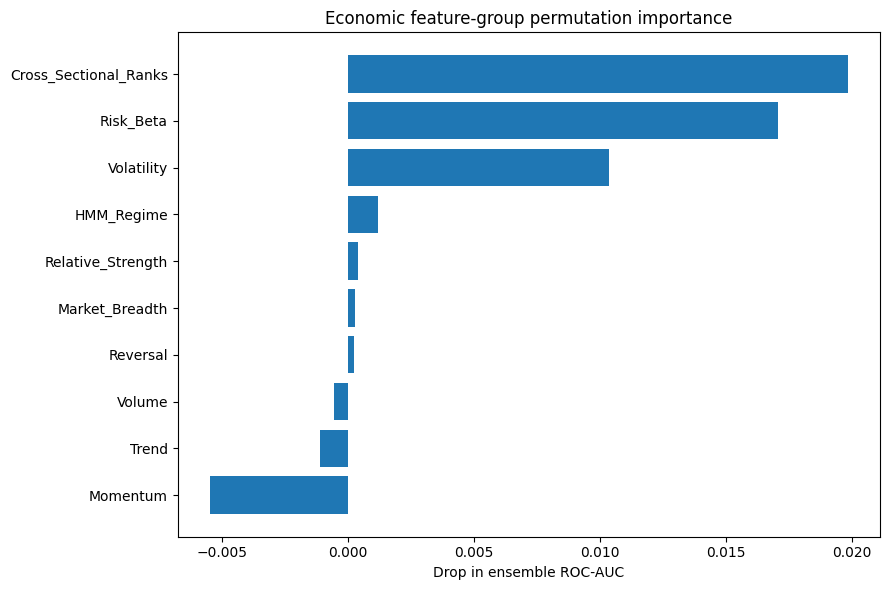

In [61]:
fig, ax = plt.subplots(figsize=(9, 6))

plot_group_importance = group_importance.sort_values("Importance_Mean")

ax.barh(
    plot_group_importance.index,
    plot_group_importance["Importance_Mean"],
)

ax.set_title("Economic feature-group permutation importance")
ax.set_xlabel("Drop in ensemble ROC-AUC")

plt.tight_layout()
plt.show()

In [62]:
yearly_group_tables = {}

for year in sorted(test["Date"].dt.year.unique()):
    frame_year = test.loc[
        test["Date"].dt.year == year
    ].copy()

    if (
        len(frame_year) < 100
        or frame_year["Target_TopQuartile_5D"].nunique() < 2
    ):
        continue

    yearly_group_tables[year] = (
        group_permutation_importance(
            frame_year,
            n_repeats=5,
        )["Importance_Mean"]
    )

if yearly_group_tables:
    yearly_feature_group_importance = pd.DataFrame(
        yearly_group_tables
    )

    display(yearly_feature_group_importance)

,2024,2025,2026
Feature_Group,,,
Cross_Sectional_Ranks,0.0121,0.0395,0.0095
HMM_Regime,0.0005,0.0006,0.0040
Market_Breadth,0.0002,0.0002,0.0010
Momentum,-0.0011,-0.0048,-0.0125
Relative_Strength,-0.0117,-0.0105,0.0299
Reversal,0.0011,-0.0004,-0.0054
Risk_Beta,0.0100,0.0169,0.0119
Trend,-0.0022,-0.0004,0.0040
Volatility,0.0148,0.0153,-0.0100


## 23.9 Model-family agreement

Pairwise correlations between calibrated model probabilities show whether the ensemble members provide genuinely differentiated information.

In [63]:
model_probability_table = pd.DataFrame(index=test.index)

for name, model in best_models.items():
    raw_probability = model.predict_proba(
        test[MODEL_FEATURES]
    )[:, 1]

    model_probability_table[name] = (
        calibrators[name]
        .predict_proba(
            raw_probability.reshape(-1, 1)
        )[:, 1]
    )

model_agreement = model_probability_table.corr()

display(model_agreement)

,Logistic,RandomForest,HGB
Logistic,1.0000,0.4491,0.3057
RandomForest,0.4491,1.0000,0.6406
HGB,0.3057,0.6406,1.0000


## 23.10 Final robustness scorecard

The scorecard summarises the evidence. It does not retune or alter the locked strategy.

In [64]:
full_regime_stats = regime_ablation_detailed.loc["ML_HMM_Trend"]
ml_only_stats = regime_ablation_detailed.loc["ML_Only"]

with_buffer_turnover = buffer_efficiency.loc[
    "Annualised_Turnover",
    "With_Buffer",
]

without_buffer_turnover = buffer_efficiency.loc[
    "Annualised_Turnover",
    "Without_Buffer",
]

cost_20bps_return = (
    expanded_cost_sensitivity.loc[
        20.0,
        "Annual_Return",
    ]
    if 20.0 in expanded_cost_sensitivity.index
    else np.nan
)

scorecard = pd.DataFrame({
    "Result": [
        test_metrics["ROC_AUC"],
        ml_precision_at_3,
        test_metrics["Mean_Top3_Relative_Log_Return"],
        strategy_stats["Sharpe"] - ftse_stats["Sharpe"],
        strategy_stats["Sharpe"] - equal_weight_stats["Sharpe"],
        full_regime_stats["Sharpe"] - ml_only_stats["Sharpe"],
        without_buffer_turnover - with_buffer_turnover,
        cost_20bps_return,
        pct_years_beating_ftse,
        group_importance["Importance_Mean"].abs().sum(),
    ],
    "Status": [
        "PASS" if test_metrics["ROC_AUC"] > 0.50 else "MIXED",
        "PASS" if ml_precision_at_3 > RANDOM_PRECISION_AT_3 else "MIXED",
        "PASS" if test_metrics["Mean_Top3_Relative_Log_Return"] > 0.0 else "MIXED",
        "PASS" if strategy_stats["Sharpe"] > ftse_stats["Sharpe"] else "MIXED",
        "PASS" if strategy_stats["Sharpe"] > equal_weight_stats["Sharpe"] else "MIXED",
        "PASS" if full_regime_stats["Sharpe"] > ml_only_stats["Sharpe"] else "MIXED",
        "PASS" if with_buffer_turnover < without_buffer_turnover else "MIXED",
        "PASS" if np.isfinite(cost_20bps_return) and cost_20bps_return > 0.0 else "MIXED",
        "PASS" if pct_years_beating_ftse >= 0.50 else "MIXED",
        "PASS" if len(group_importance) > 0 else "MIXED",
    ],
}, index=[
    "ROC-AUC above chance",
    "Precision@3 above random",
    "Positive realised top-3 relative return",
    "Net Sharpe above FTSE",
    "Net Sharpe above equal-weight",
    "Combined regime overlay improves Sharpe",
    "Buffer reduces annualised turnover",
    "Positive return at 20 bps",
    "At least half of years beat FTSE",
    "Feature-group interpretation available",
])

display(scorecard)

,Result,Status
ROC-AUC above chance,0.5447,PASS
Precision@3 above random,0.3099,PASS
Positive realised top-3 relative return,0.0036,PASS
Net Sharpe above FTSE,0.3182,PASS
Net Sharpe above equal-weight,0.0384,PASS
Combined regime overlay improves Sharpe,-0.4484,MIXED
Buffer reduces annualised turnover,13.6034,PASS
Positive return at 20 bps,0.2251,PASS
At least half of years beat FTSE,0.6667,PASS
Feature-group interpretation available,0.0565,PASS


# 24. Updated PGFM04 interpretation guide

The report should now distinguish three forms of evidence:

### Predictive skill
Use ROC-AUC, Precision@3, lift over the 25% random baseline and realised top-3 relative return.

### Economic performance
Use annualised return, Sharpe, Sortino, maximum drawdown, VaR, Expected Shortfall, final portfolio value and transaction-cost drag.

### Robustness
Use regime decomposition, buffer efficiency, higher-cost sensitivity, break-even cost, yearly performance, rolling Sharpe, turnover efficiency, feature-group importance and model-family agreement.

The 2024+ locked test must remain diagnostic only. None of these robustness outputs should be used to redesign the already tested strategy.